# Sample exclusions and career-level imbalance

This version adds a row-level exclusion audit and repeated equal-size sensitivity analysis. **Run the single code cell.** The code remains self-contained and supports Colab; upload the workbook or supply its path. Locally, use a working notebook kernel with NumPy, pandas, NetworkX, Matplotlib, and openpyxl.

`MIN_VALID_SKILLS = 1` excludes a posting if **none** of its five skill fields contains a substantive skill. Blank values and “Not Specified” are ignored. A posting with valid skills and some unspecified slots remains eligible. Duplicate skill mentions count once. A one-skill posting contributes to prevalence and node coverage; it creates no skill-pair edge. Forcing all five slots to be populated could select more extensively coded postings. Set the minimum to 2–5 only as an explicit alternative; `minimum_skill_threshold_counts.csv` shows the resulting sample sizes.

For the supplied workbook, the exclusion ledger reconciles to 10,024 postings:

| | At least one valid skill | No valid skill | Total |
|---|---:|---:|---:|
| Known career level | 7,686 | 324 | 8,010 |
| Unspecified career level | 1,572 | 442 | 2,014 |
| Total | 9,258 | 766 | 10,024 |

The **442** rows in the lower-right cell belong to both missingness categories. They must not be subtracted twice. Career-level analyses retain **10,024 − 2,014 − 324 = 7,686** postings. The pooled degree–constraint network now uses the **same 7,686 postings** with recorded skills and known career levels. The 1,572 skill-bearing postings with unspecified levels are excluded from this primary sample; the previous 9,258-posting results remain available as a broader-sample comparison. An unknown career level is not imputed as Mid. All counts and exclusions are recalculated from the workbook.

## How the sensitivity check addresses imbalance

The primary analysis retains all eligible postings: Entry 737, Mid 3,033, Senior 3,755, Executive 161. These are samples of advertised demand, not a balanced training dataset. Prevalence uses each network's own posting denominator; cross-level betweenness uses its lower–higher posting-pair denominator. Such normalization does not remove sample-size effects on which skills and ties are observed, graph structure, or uncertainty.

By default, **100 repeated draws select 161 original postings from each level, without replacement within a draw**. Networks and scores are recomputed for every draw. The career-level degree–constraint check compares equally sized level networks. The cross-level check uses 161 postings on each side of every selected comparison, with the same sampled level shared across comparisons in a repetition. Full-sample outputs are retained separately. No duplicated or synthetic postings are added.

Each draw recalculates category cutoffs using the same selected method and equality rule as the primary analysis. The default method is the arithmetic mean across eligible skills within that draw. A skill absent from a draw is marked **Not observed**, not assigned to a low category. Degree/constraint/betweenness summaries are conditional on observation and a defined measure; prevalence can be zero. Results report detection rates, classification rates, category agreement with the full-sample result, and all category frequencies. Changes can arise from both scores and cutoffs.

The 2.5th–97.5th percentile ranges describe **sensitivity to subsampling**, not population confidence intervals. With 161 postings per level, all Executive postings appear in every draw; this does not estimate Executive sampling uncertainty. Equalizing sample counts also does not equalize skill annotation completeness, industries, role composition, or selection bias. The audit reports valid-skill counts and missing-skill rates by level so these differences remain visible.

New outputs include `sample_exclusion_ledger.csv`, `sample_row_audit.csv`, `level_sample_audit.csv`, `valid_skill_count_distribution.csv`, `minimum_skill_threshold_counts.csv`, and `sample_exclusion_summary.json`. Sensitivity outputs include `balanced_skill_summary.csv`, `balanced_category_frequencies.csv`, all skill-level draws, draw diagnostics, and sampled posting row IDs. Seeds, sample sizes, and limitations are recorded in `balanced_sensitivity_metadata.json`.

The notebook below uses mean cutoffs for the primary analysis and every sensitivity draw. Networks and raw scores are unchanged by the choice of cutoff; median classifications are also exported for comparison.


# Skill Connectivity Matrix: mean cutoffs

**Run the single code cell below.** Everything is included in this notebook. Locally, use a working Python kernel with the required packages. In Colab, upload the workbook or set `INPUT_FILE` to its Drive path and enable the optional Drive mount. The source workbook is read only.

The primary analysis maps the **pooled marketing skill network using the known-career-level sample** (`OVERALL_SAMPLE = "known_level"`). With the supplied workbook, the pooled network and the career-level analyses use the same 7,686 postings. Set `OVERALL_SAMPLE = "all_skill_bearing"` to reproduce the previous 9,258-posting sample. Optional comparisons construct separate networks for Entry, Mid, Senior, and Executive postings. These are neither cumulative nor cross-level betweenness networks. The four labels here describe **degree × constraint**, and are distinct from Catalyst, Accelerator, Gateway, and Niche in the prevalence–betweenness analysis.

| | Lower degree | Higher degree |
|---|---|---|
| **Higher constraint** | **Focused anchors:** fewer associates relative to the reference network, with comparatively concentrated and/or locally reinforced associations. | **Embedded hubs:** more associates, with comparatively concentrated and/or locally reinforced associations. |
| **Lower constraint** | **Selective connectors:** fewer associates, with comparatively lower aggregate constraint within that set of relationships. | **Broad connectors:** more associates, with comparatively lower aggregate constraint across those relationships. |

“Higher” and “lower” are relative classifications. “Connector” describes observed co-occurrence relationships; it does not establish brokerage between distinct domains or career mobility. Empty categories are reported rather than forced to contain skills.

## What the measures mean

**Degree counts distinct associated competencies.** If Communication appears alongside Data Analytics in 100 postings and Brand Management in 10, its degree in this example is **2**, while its co-occurrence strength is **110**. Degree measures observed breadth; strength measures total tie weight. Both are exported and kept separate.

**Weighted network constraint describes concentration and local reinforcement.** Let $w_{ij}$ be the number of postings requesting skills $i$ and $j$ together, and let $p_{ij}=w_{ij}/\sum_k w_{ik}$. For an undirected graph without self-loops:

$$C_i=\sum_{j\in N(i)}\left(p_{ij}+\sum_q p_{iq}p_{qj}\right)^2.$$

The first term reflects the focal skill's allocation of tie weight. The second reflects connections through associated skills. The notebook uses `nx.constraint(G, weight='weight')`, checked against this formula. Positive co-occurrence counts are tie strengths. They are not shortest-path distances.

Higher constraint indicates greater concentration of observed relationships, reinforcement through connected neighbors, or both. Lower constraint can reflect more evenly distributed tie weights, weaker indirect reinforcement, a larger number of associates, or a combination. **Degree establishes how many associates a skill has; constraint helps explain how those relationships are organized.** Lower constraint alone does not establish broader applicability or productive complementarity.

Two diagnostic columns make the calculation easier to interpret: `direct_concentration` is $\sum_j p_{ij}^2$; `indirect_reinforcement` is $C_i-\sum_j p_{ij}^2$. The latter includes the cross terms and squared indirect contributions in the constraint formula. They sum to constraint. It is not a causal estimate of the contribution of neighbors. `skill_associations.csv` lists every neighbor, its co-occurrence count, tie-weight share, and local constraint contribution.

A skill with one neighbor has constraint 1 even without a dense cluster. An equally weighted three-node triangle gives constraint 1.125, so constraint is **not a percentage and is not clipped to 1**. An isolated skill has degree 0 and undefined constraint: it remains in outputs but is unclassified. Redundancy here means overlapping network connections, not unnecessary skills.

Definitions: [NetworkX constraint](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.structuralholes.constraint.html) and [local constraint](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.structuralholes.local_constraint.html).


Starting degree–constraint analysis. Wait for DEGREE–CONSTRAINT ANALYSIS COMPLETE.


Classification cutoffs: separate arithmetic means within each network; equality is lower.


[1/4] Reading and validating marketing skills...


Overall sample: known_level; 7,686 eligible postings.


[2/4] Computing distinct-neighbor degree and weighted constraint...


...

Skill type,Count,Skills
Focused anchors,7,1. Account-Based Marketing2. AI/Machine Learning in Marketing3. Content Marketing4. Event Management5. Influencer Marketing6. Market Research7. Salesforce Marketing Cloud
Embedded hubs,9,1. Adobe Creative Suite2. Brand Management3. Copywriting4. Digital Marketing5. Email Marketing6. Marketing Automation7. PPC/Paid Advertising8. SEO/SEM9. Video/Multimedia Production
Selective connectors,5,1. A/B Testing2. Google Marketing Platform3. Project Management4. Strategic Planning5. WordPress/CMS
Broad connectors,13,1. Budget Management2. Communication Skills3. CRM4. Customer Engagement5. Data Analytics6. Demand Generation7. eCommerce8. Graphic Design9. HTML/CSS10. Leadership/Team Management11. Public Relations12. Social Media Marketing13. SQL/Database


Skill type,Count,Skills
Focused anchors,9,1. A/B Testing2. Account-Based Marketing3. Adobe Creative Suite4. AI/Machine Learning in Marketing5. Content Marketing6. Event Management7. Google Marketing Platform8. Influencer Marketing9. Video/Multimedia Production
Embedded hubs,11,1. Brand Management2. Budget Management3. Communication Skills4. Customer Engagement5. Demand Generation6. eCommerce7. Market Research8. Marketing Automation9. PPC/Paid Advertising10. SQL/Database11. Strategic Planning
Selective connectors,5,1. Copywriting2. Email Marketing3. HTML/CSS4. Salesforce Marketing Cloud5. WordPress/CMS
Broad connectors,9,1. CRM2. Data Analytics3. Digital Marketing4. Graphic Design5. Leadership/Team Management6. Project Management7. Public Relations8. SEO/SEM9. Social Media Marketing


Skill type,Count,Skills
Focused anchors,15,1. AI/Machine Learning in Marketing2. Content Marketing3. Copywriting4. Demand Generation5. eCommerce6. Event Management7. Google Marketing Platform8. Graphic Design9. HTML/CSS10. Market Research11. Marketing Automation12. Project Management13. SQL/Database14. Strategic Planning15. Video/Multimedia Production
Embedded hubs,1,1. Brand Management
Selective connectors,5,1. Adobe Creative Suite2. Customer Engagement3. Email Marketing4. Influencer Marketing5. WordPress/CMS
Broad connectors,10,1. Budget Management2. Communication Skills3. CRM4. Data Analytics5. Digital Marketing6. Leadership/Team Management7. PPC/Paid Advertising8. Public Relations9. SEO/SEM10. Social Media Marketing


All overall-network scores (the CSV retains full numeric precision):


skill_label,degree,constraint,category,cooccurrence_strength,prevalence,direct_concentration,indirect_reinforcement
A/B Testing,21,0.28297,Selective connectors,86,0.00299,0.08924,0.19373
Account-Based Marketing,21,0.33064,Focused anchors,291,0.01002,0.12755,0.20309
Adobe Creative Suite,30,0.34737,Focused anchors,2282,0.07676,0.12426,0.22311
AI/Machine Learning in Marketing,29,0.29008,Selective connectors,369,0.01392,0.09660,0.19348
Brand Management,31,0.32091,Embedded hubs,3509,0.12959,0.09782,0.22308
Budget Management,33,0.29825,Embedded hubs,3938,0.15235,0.08894,0.20931
Communication Skills,33,0.29897,Embedded hubs,4700,0.21715,0.08895,0.21002
Content Marketing,30,0.33248,Focused anchors,1368,0.04957,0.10732,0.22515
Copywriting,30,0.29368,Selective connectors,962,0.03669,0.07954,0.21414
CRM,33,0.27724,Broad connectors,4752,0.17473,0.07915,0.19808


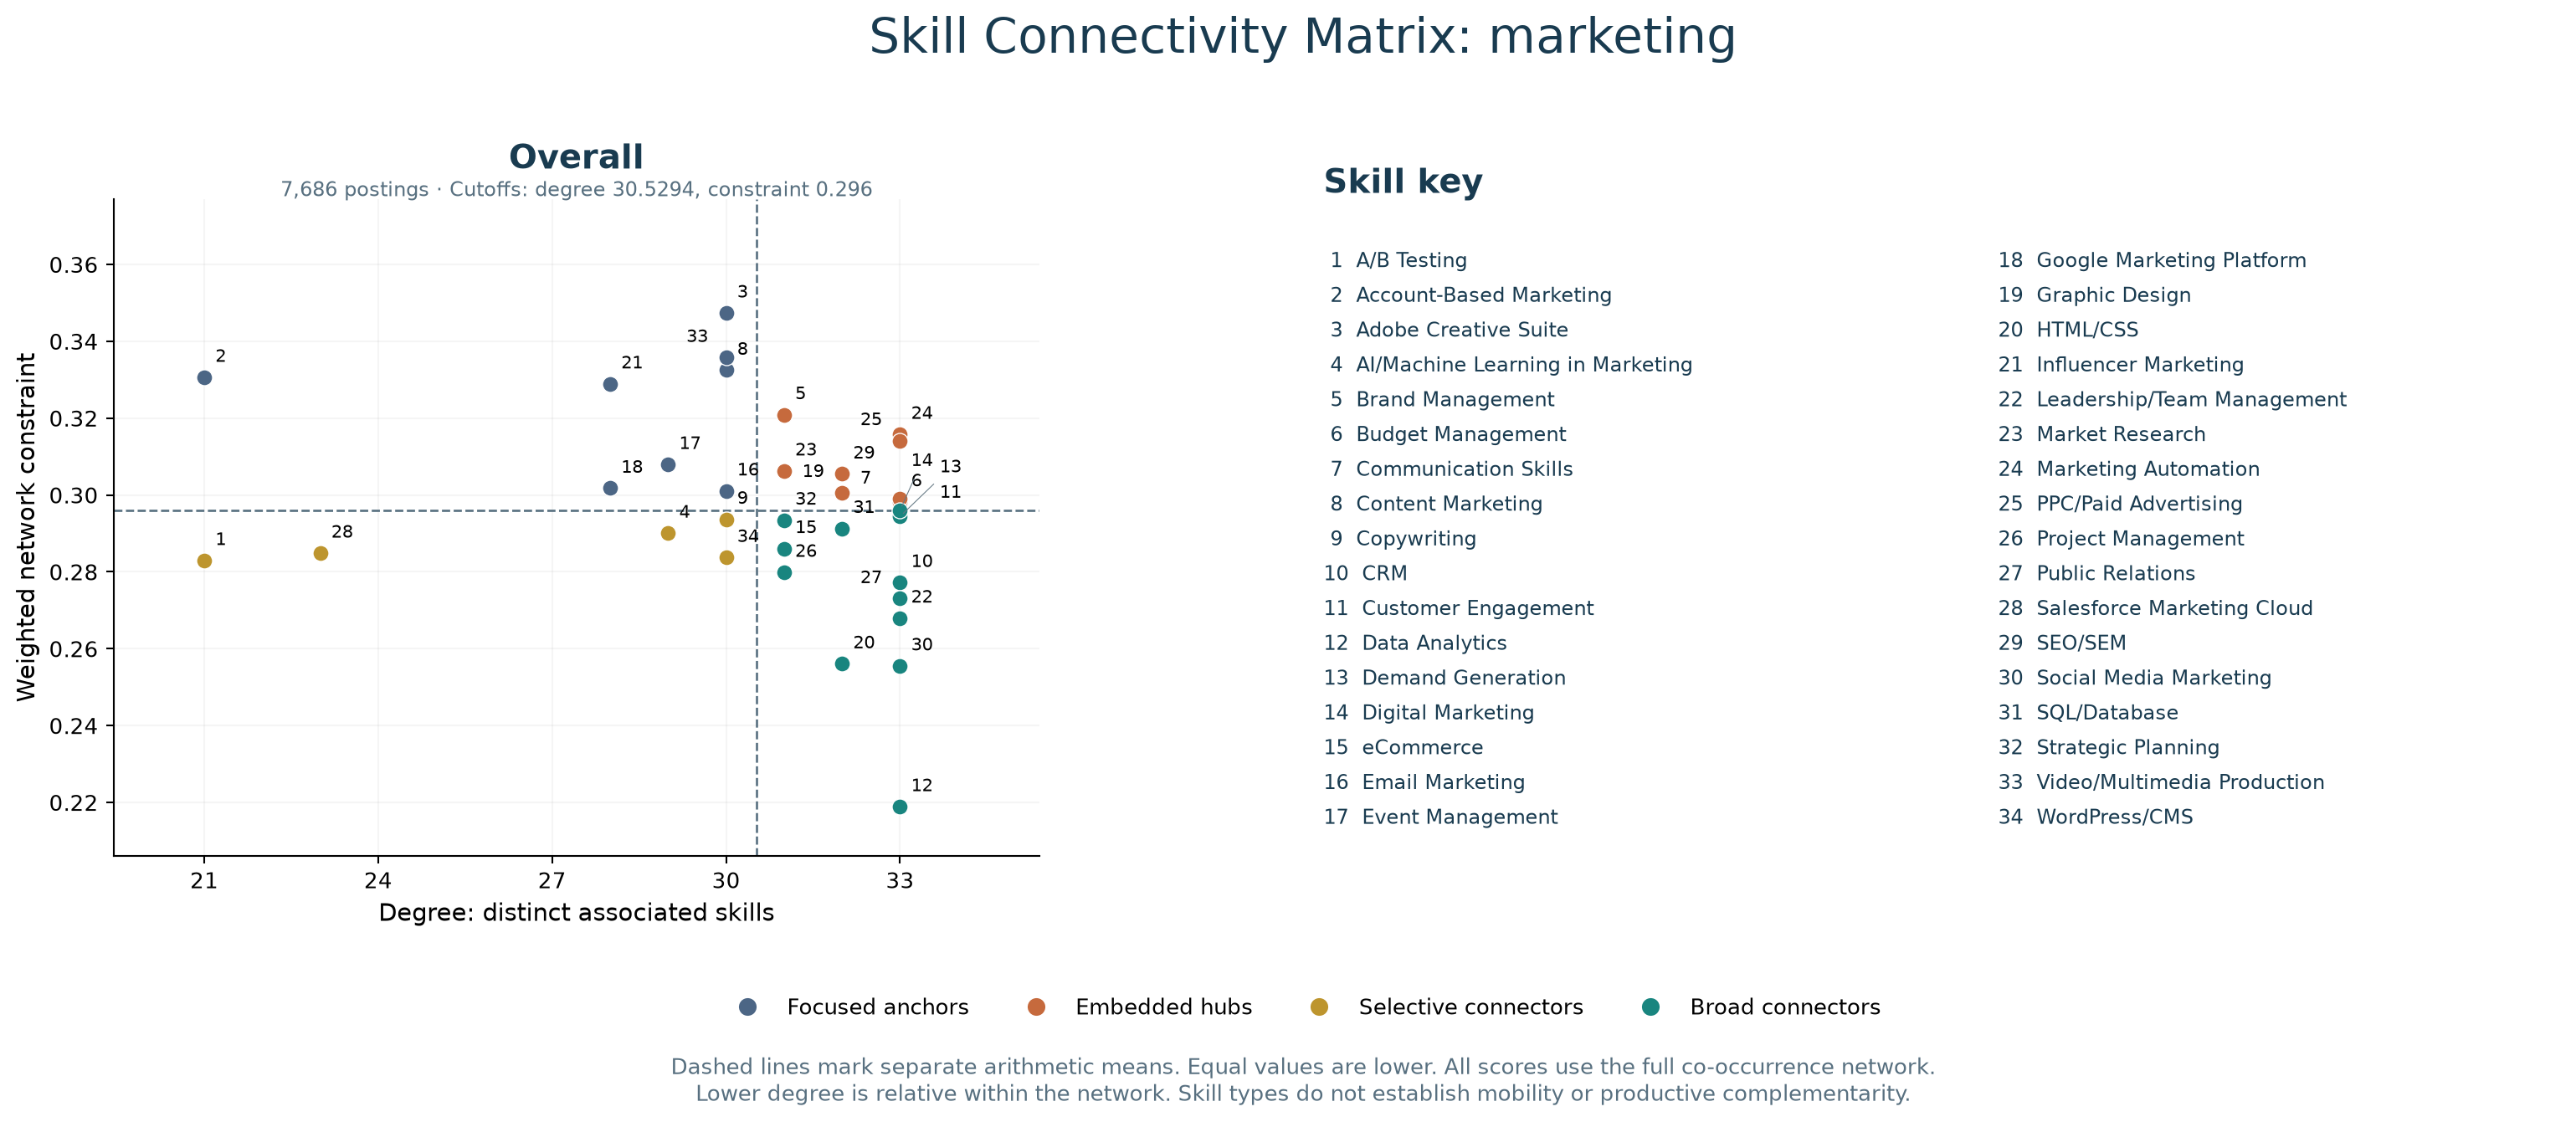

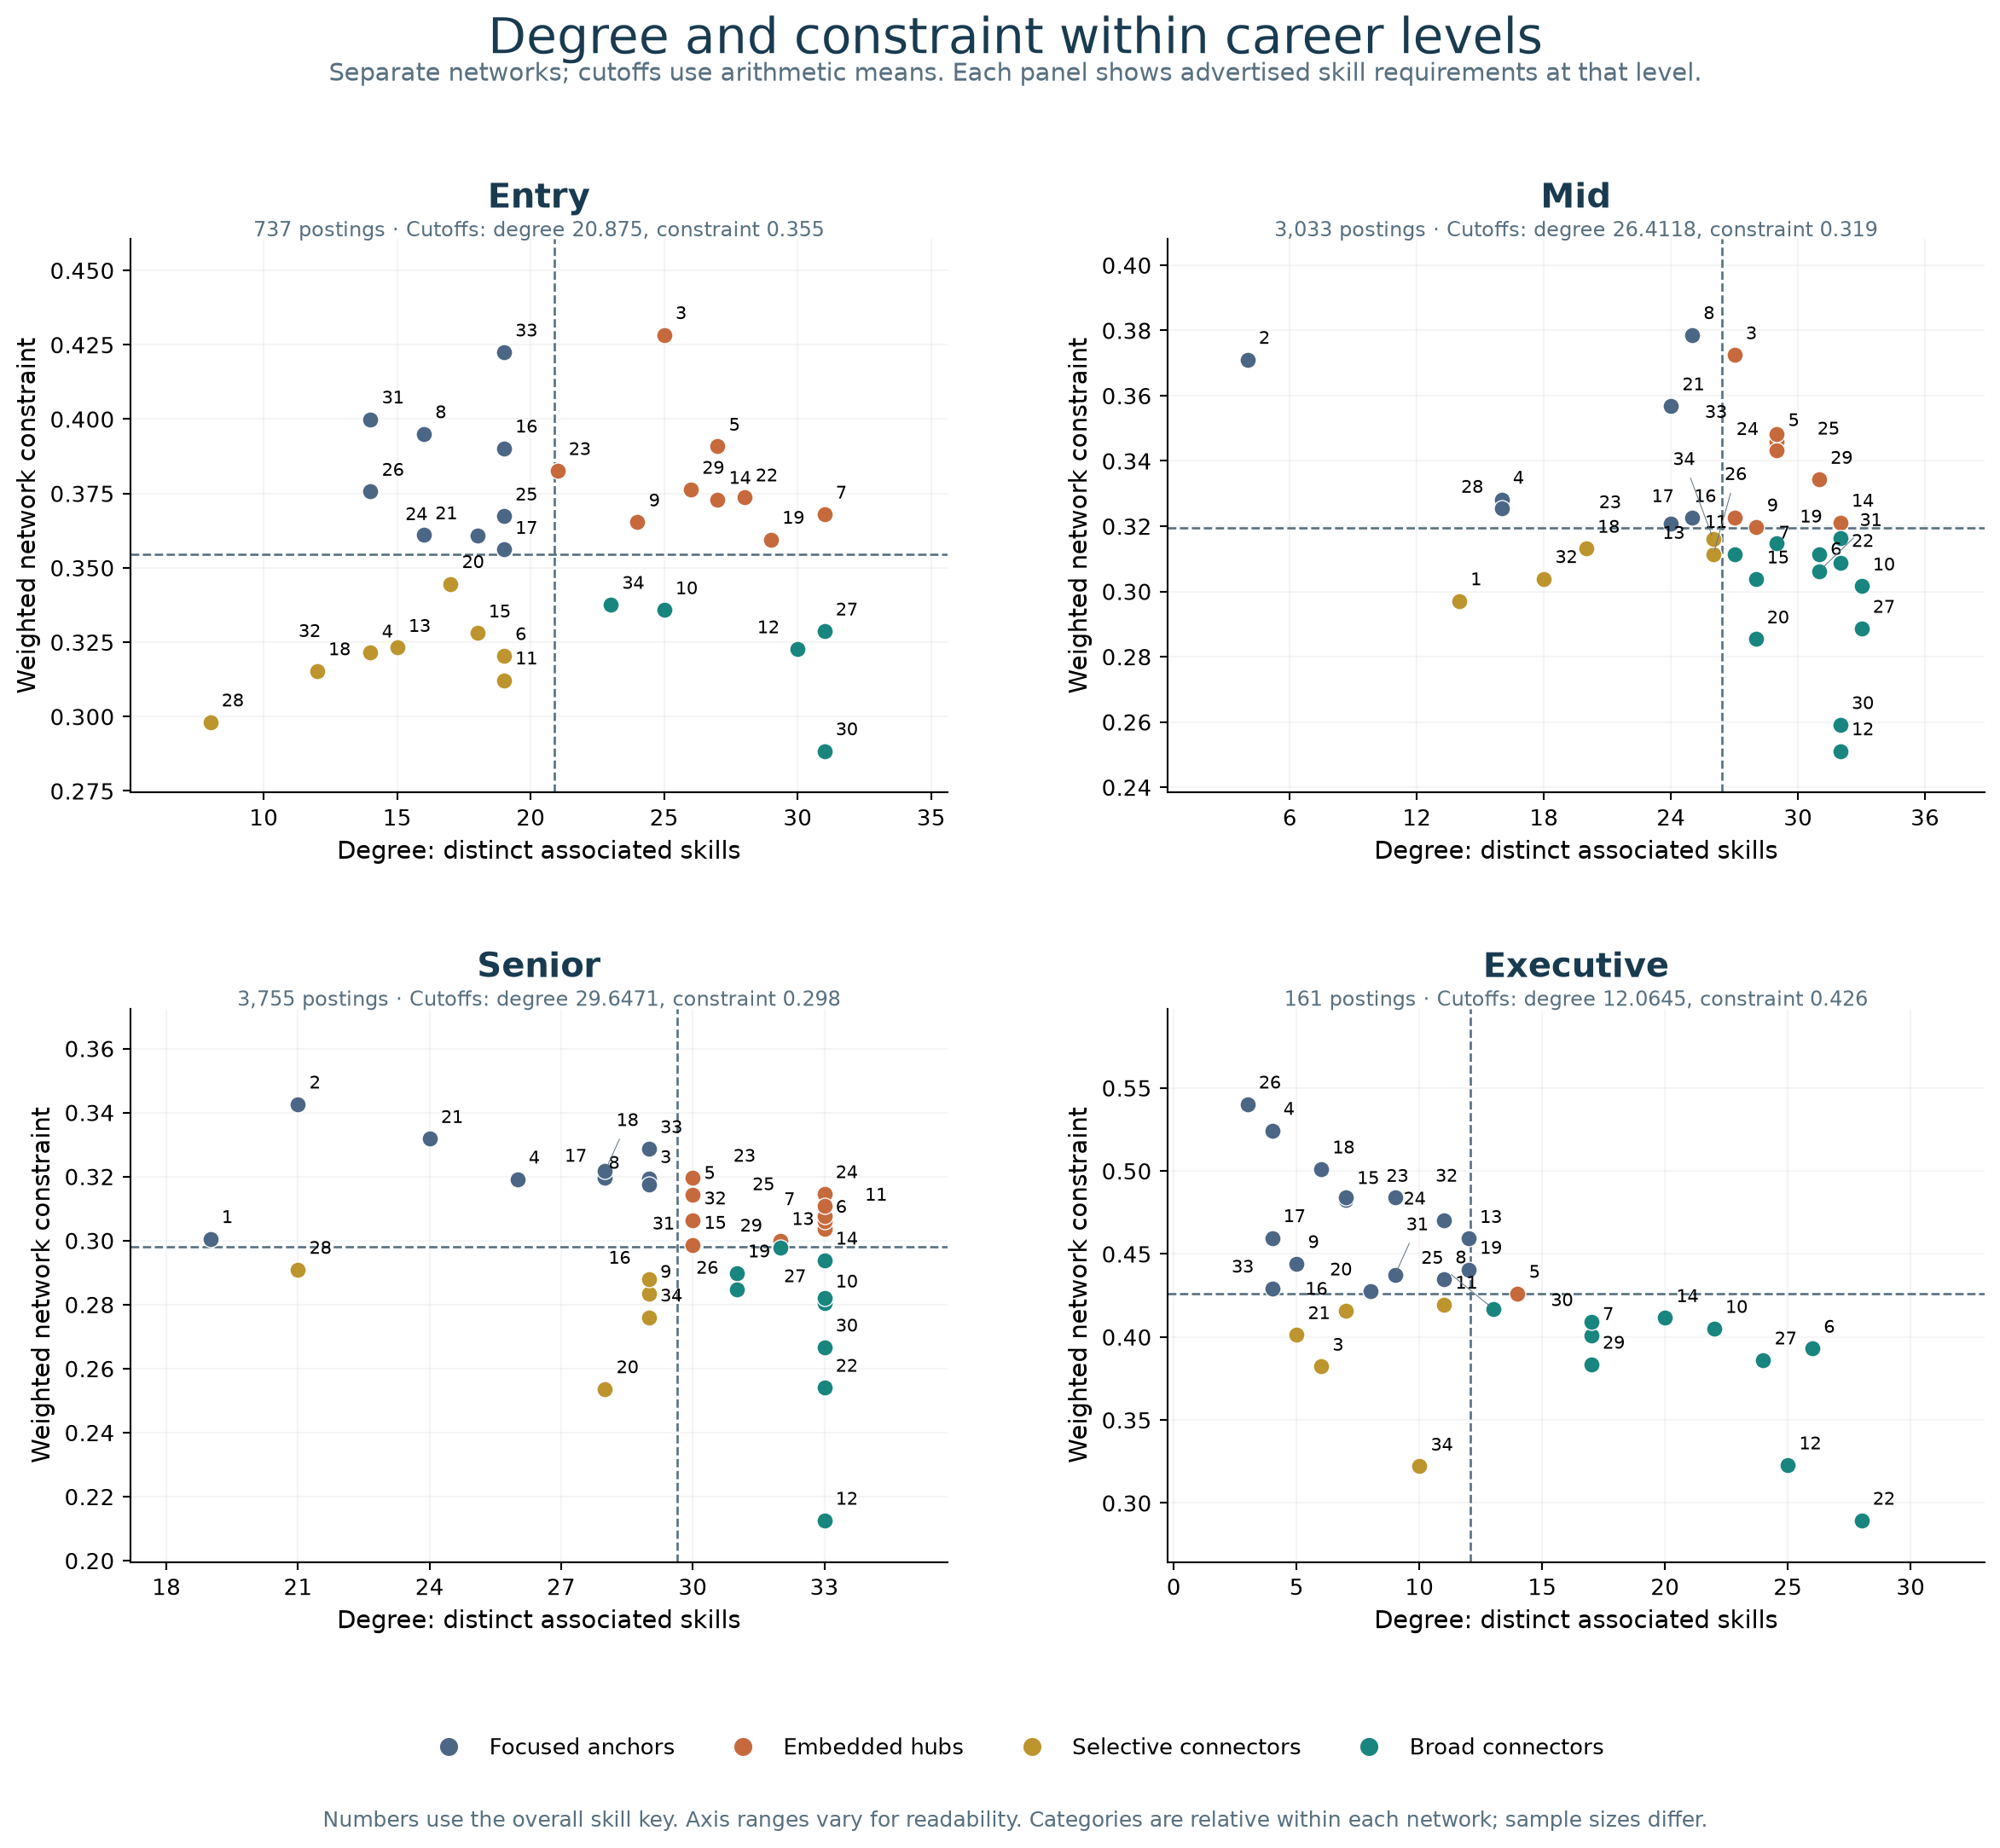

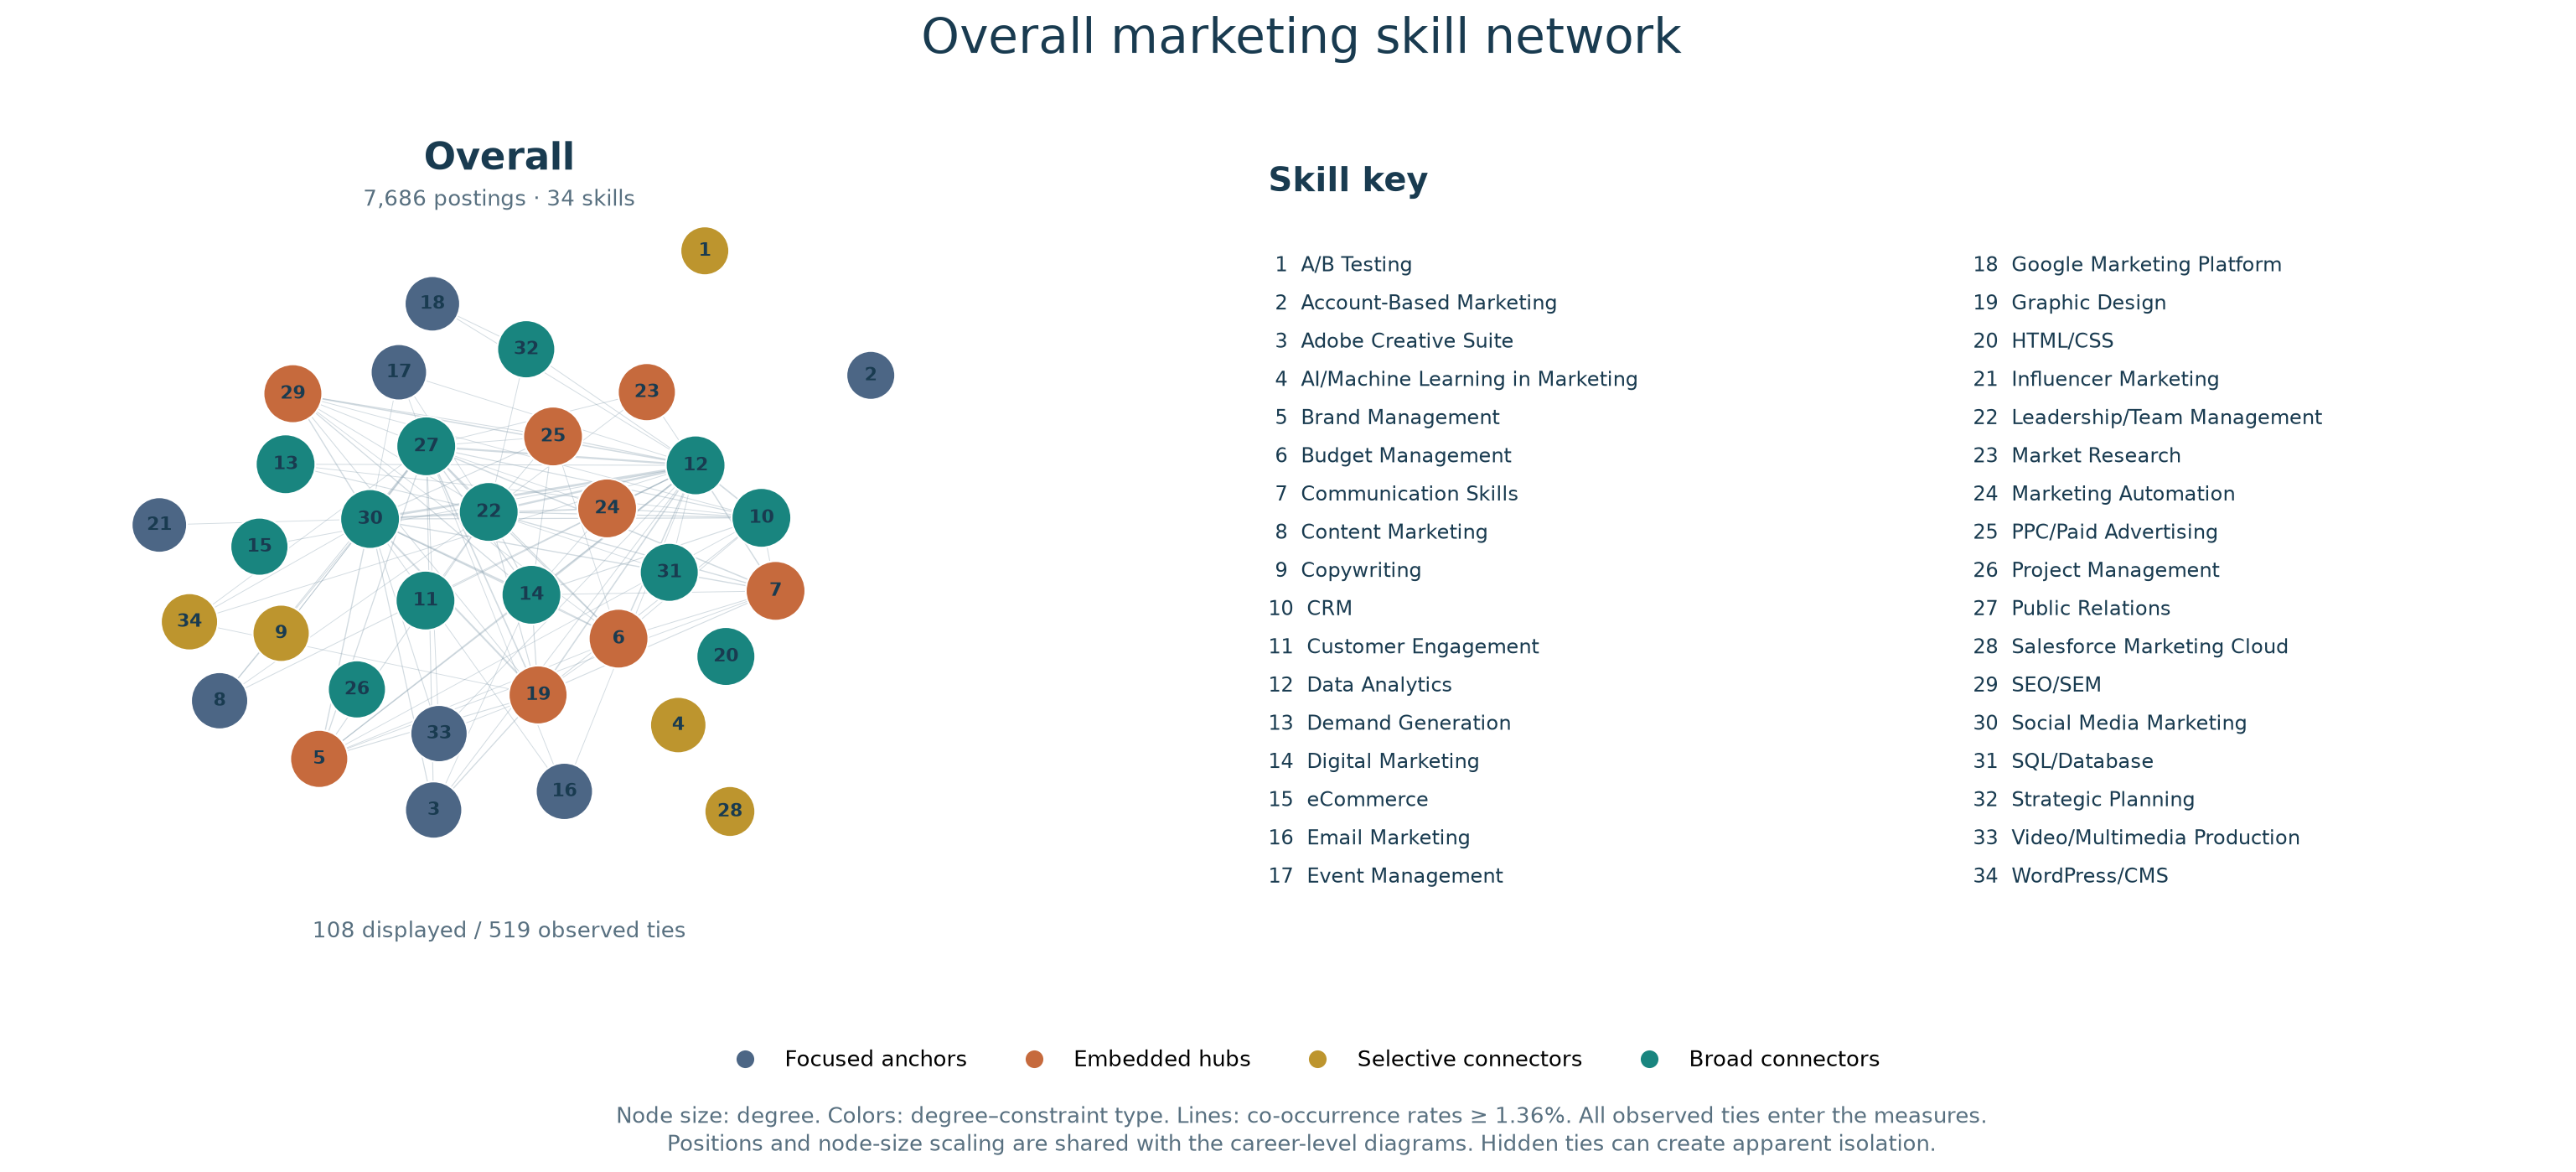

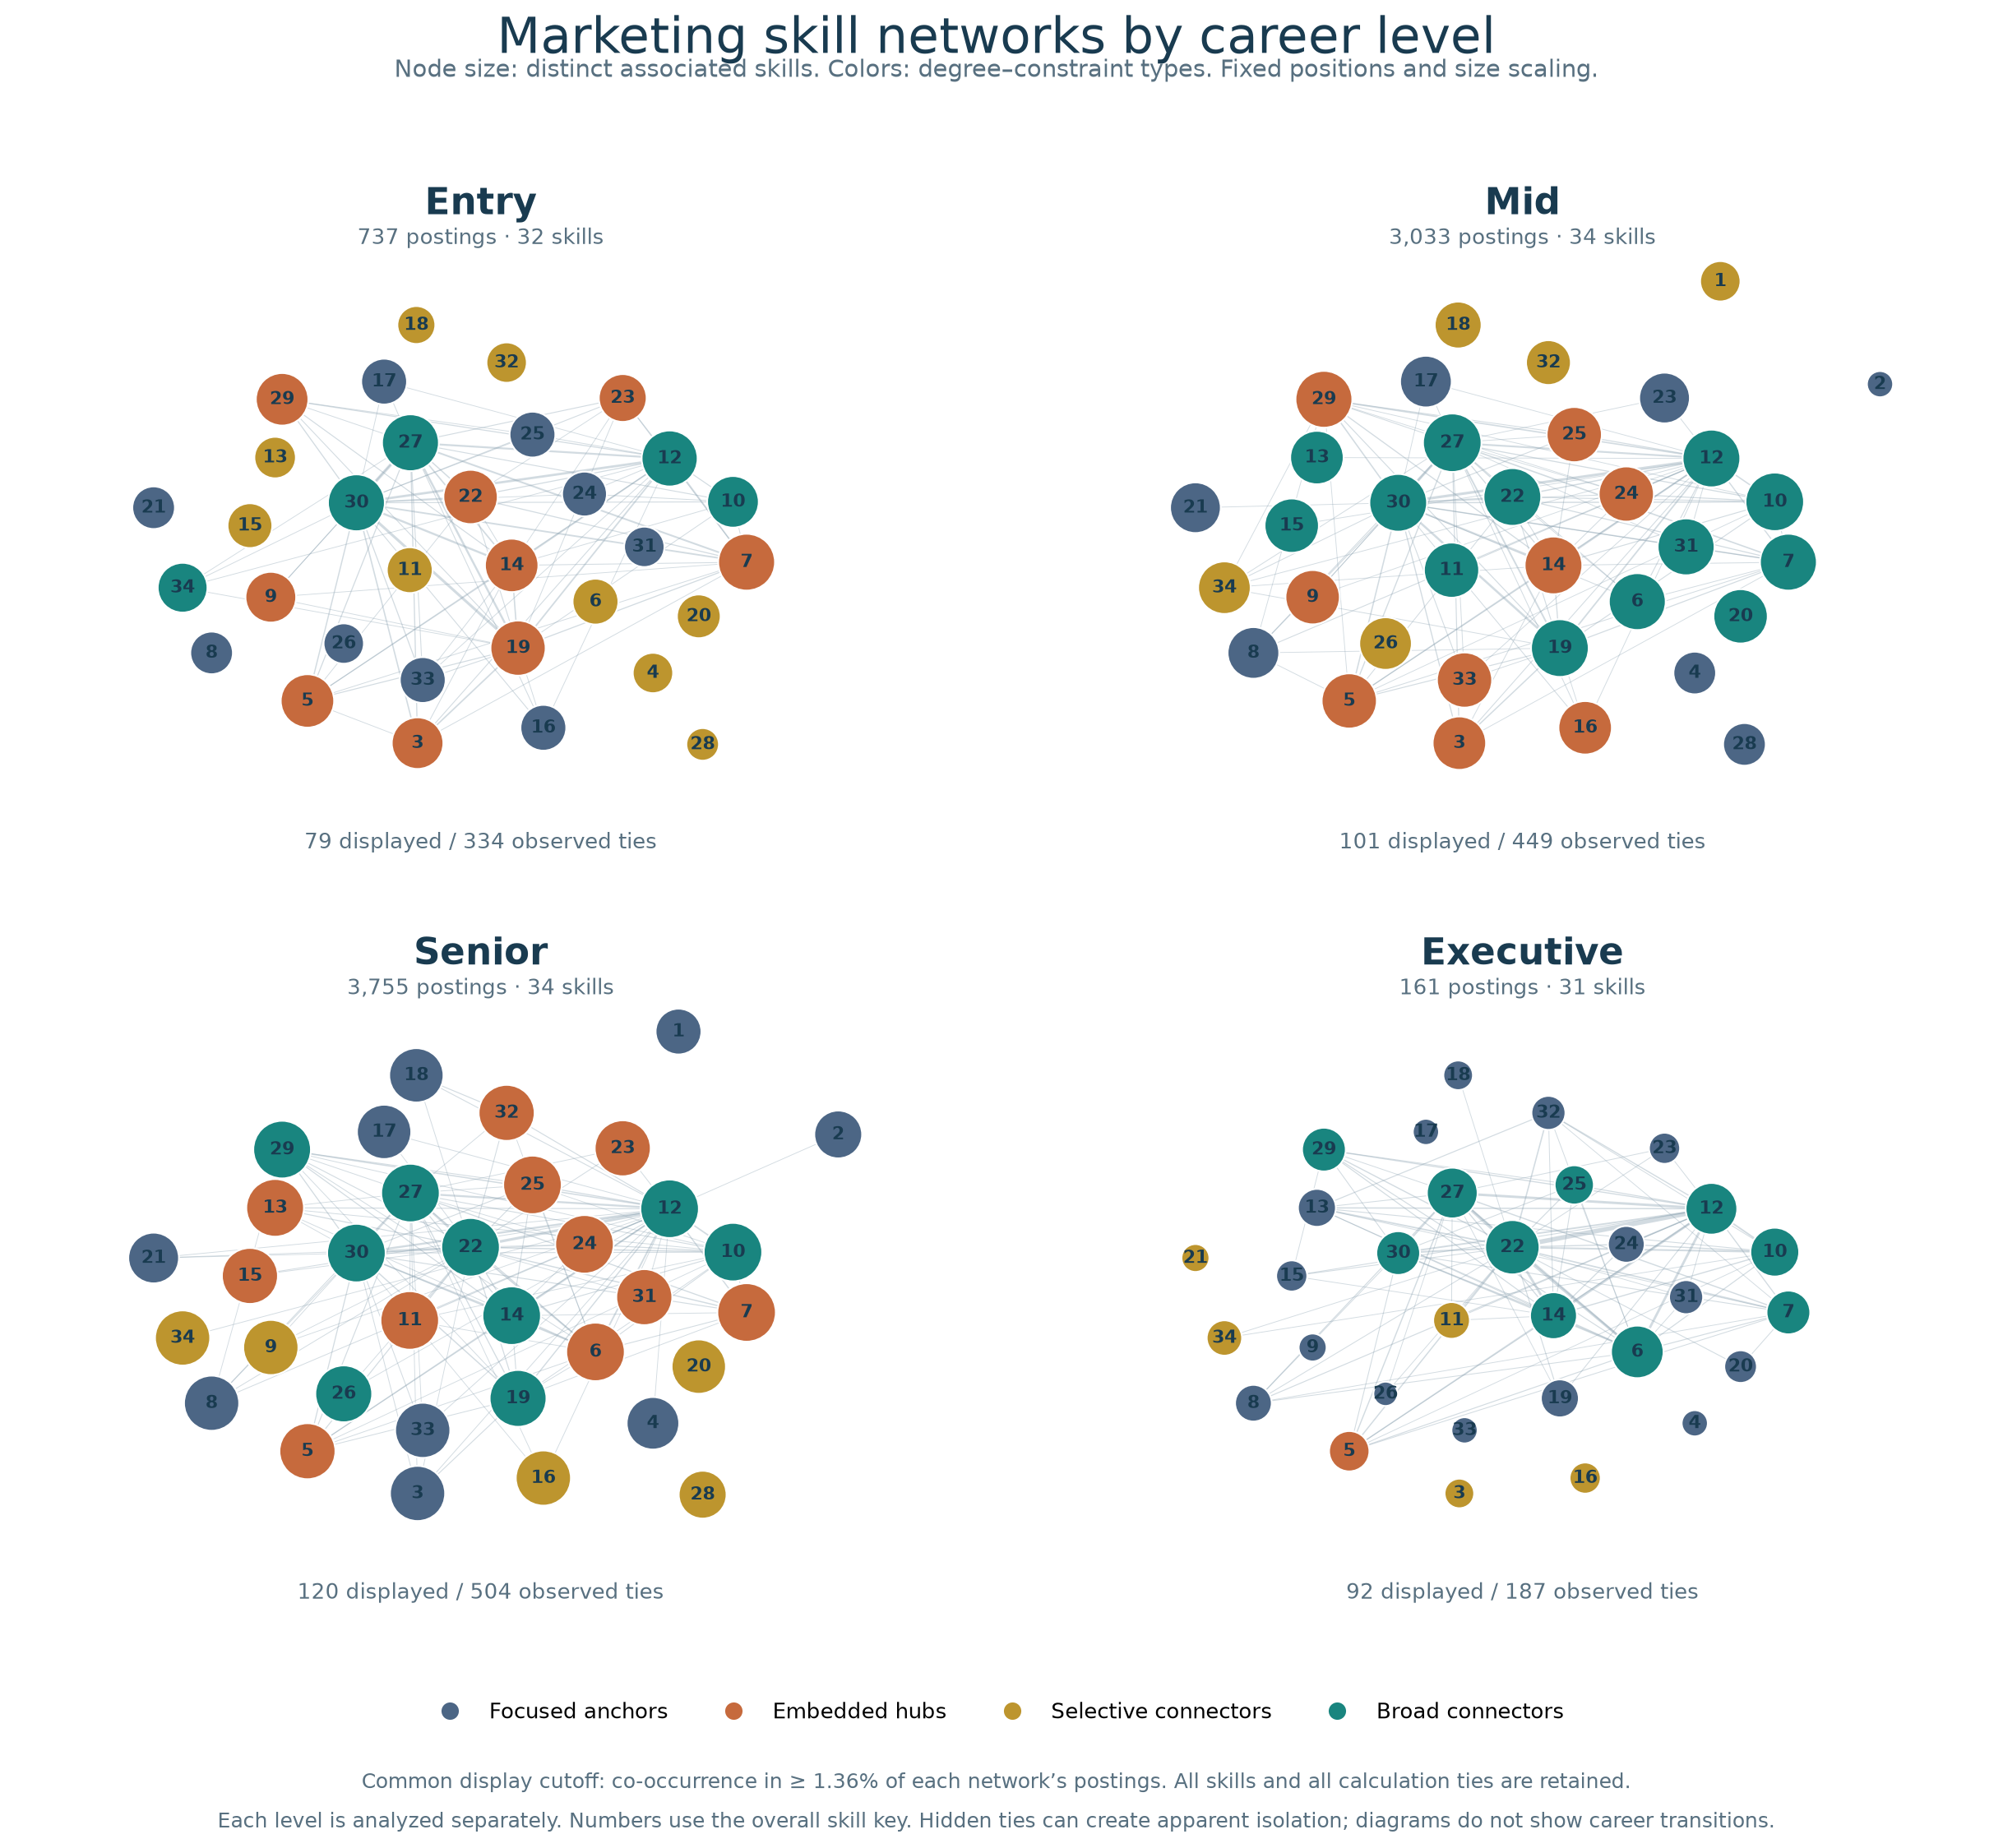

All output files: /Users/luna/Library/Mobile Documents/com~apple~CloudDocs/Desktop/projects/JobAnalysis/output/constraint_degree_mean_known_level_20261001_151422_123326
DEGREE–CONSTRAINT ANALYSIS COMPLETE


In [1]:
# RUN THIS SINGLE CELL. The complete analysis is included below these settings.
INPUT_FILE = None  # Finds US_Marketing_Jobs_Recoded.xlsx beside this project; otherwise enter its full path.
SHEET_NAME = 'Marketing Jobs - Recoded'
OUTPUT_DIR = None  # Creates a new dated results folder, preserving earlier runs.
INCLUDE_LEVEL_NETWORKS = True  # Pooled network plus separate Entry, Mid, Senior, Executive networks.
OVERALL_SAMPLE = "known_level"  # Same cohort as career-level analyses; "all_skill_bearing" reproduces the broader sample.
CUTOFF_METHOD = "mean"  # Arithmetic means across eligible skills within each network; alternatives: "median", "quantile".
CUTOFF_QUANTILE = 0.50  # Used only when CUTOFF_METHOD = "quantile".
EDGE_DISPLAY_QUANTILE = 0.75  # Filters visible lines only; all observed ties enter the calculations.
LAYOUT_SEED = 42
CUSTOM_LEVEL_MAPPING = None  # Optional complete mapping of exact job-level labels.
MIN_VALID_SKILLS = 1  # Exclude postings with NO valid skill. Set 2–5 only for a stated completeness sensitivity.
BALANCE_REPEATS = 100  # Equal-size sensitivity draws; primary full-sample analysis stays intact. Use 0 to disable.
BALANCE_SAMPLE_SIZE = None  # Smallest eligible career level (161 in the supplied workbook).
BALANCE_SEED = 2026
MOUNT_GOOGLE_DRIVE = False  # Set True only when running in Colab with a workbook on Drive.

print('Starting degree–constraint analysis. Wait for DEGREE–CONSTRAINT ANALYSIS COMPLETE.', flush=True)
import importlib.util, subprocess, sys
try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False
requirements = {'numpy': 'numpy>=1.24', 'pandas': 'pandas>=2.0', 'networkx': 'networkx>=3.2',
                'matplotlib': 'matplotlib>=3.8', 'openpyxl': 'openpyxl>=3.1'}
missing = [r for m,r in requirements.items() if importlib.util.find_spec(m) is None]
if missing:
    if IN_COLAB:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    else:
        raise RuntimeError('Use a working Python kernel or Colab. Install these missing packages in that kernel: ' + ', '.join(missing))
if MOUNT_GOOGLE_DRIVE:
    if not IN_COLAB:
        raise RuntimeError('Drive mounting is only available in Google Colab.')
    from google.colab import drive
    drive.mount('/content/drive')


from collections import Counter
from itertools import combinations
from pathlib import Path
from datetime import datetime, timezone
from html import escape
import hashlib, json, math, os, platform, tempfile, time, unicodedata
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'marketing_skill_matplotlib'))
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
LEVELS = ('entry', 'mid', 'senior', 'executive')
LEVEL_MAPPING = {
    'intern/entry-level': 'entry', 'coordinator/associate': 'mid',
    'mid-level/specialist': 'mid', 'supervisor': 'mid',
    'manager': 'senior', 'senior': 'senior', 'director': 'senior',
    'vice president': 'executive', 'c-suite/executive': 'executive',
    'not specified': None, '': None,
}
MISSING = {'', 'not specified', 'n/a', 'na', 'none', 'nan', 'not available'}
SKILL_COLUMNS = tuple(f'Key Skill {i}' for i in range(1,6))
COLORS = {'Focused anchors': '#4C6685', 'Embedded hubs': '#C66A3D',
          'Selective connectors': '#BD952E', 'Broad connectors': '#19857F'}
UNCLASSIFIED = 'Unclassified (no co-occurrences)'


def normalize(value):
    if value is None or pd.isna(value):
        return ""
    return " ".join(unicodedata.normalize("NFKC", str(value)).split())

def hash_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def resolve_input(input_path=None):
    if input_path is not None:
        path = Path(input_path).expanduser().resolve()
        if not path.is_file():
            raise FileNotFoundError(f"Workbook not found: {path}")
        return path
    script_folder = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
    roots = [Path.cwd(), script_folder, Path("/Users/sfy5287/Desktop/projects/JobAnalysis")]
    roots += list(Path.cwd().parents)[:3] + list(script_folder.parents)[:3]
    # Search locally; Drive access is never mounted implicitly.
    for name in ("US_Marketing_Jobs_Recoded.xlsx", "US_Marketing_Jobs_Recoded (1).xlsx"):
        for root in dict.fromkeys(roots):
            path = root / name
            if path.is_file():
                return path.resolve()
    raise FileNotFoundError("Set INPUT_FILE in the notebook, or pass --input /path/to/workbook.xlsx. In Colab, upload the workbook or explicitly mount Drive first.")

def prepare_data(frame, level_mapping=None, missing_skill_policy="exclude"):
    """Clean skill mentions and map observed level labels without guessing."""
    if missing_skill_policy not in {"exclude", "retain"}:
        raise ValueError("missing_skill_policy must be 'exclude' or 'retain'.")
    frame = frame.copy()
    frame.columns = [normalize(c) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError("Duplicate column names after normalization.")
    needed = ["Job Level", *SKILL_COLUMNS]
    absent = [c for c in needed if c not in frame]
    if absent:
        raise ValueError(f"Required columns missing: {absent}")
    supplied = LEVEL_MAPPING if level_mapping is None else level_mapping
    mapping = {normalize(k).casefold(): normalize(v).casefold() if v is not None else None for k, v in supplied.items()}
    if len(mapping) != len(supplied) or any(v is not None and v not in LEVELS for v in mapping.values()):
        raise ValueError("Level mapping must have unique normalized labels and map to entry, mid, senior, executive, or null.")
    records, display_counts, unmapped = [], {}, Counter()
    for offset, (_, row) in enumerate(frame.iterrows(), 2):
        if row.isna().all():
            continue
        raw_level = normalize(row["Job Level"])
        key = raw_level.casefold()
        if key not in mapping:
            unmapped[raw_level] += 1
            continue
        skills, duplicates, missing_cells = set(), 0, 0
        for col in SKILL_COLUMNS:
            label = normalize(row[col])
            skill = label.casefold()
            if skill in MISSING:
                missing_cells += 1
                continue
            display_counts.setdefault(skill, Counter())[label] += 1
            duplicates += skill in skills
            skills.add(skill)
        level = mapping[key]
        reason = "unspecified_or_excluded_level" if level is None else "no_substantive_skills" if not skills and missing_skill_policy == "exclude" else "included"
        records.append({"excel_row": offset, "posting_id": normalize(row.get("No", offset - 1)), "raw_job_level": raw_level, "stratum": level, "skills": tuple(sorted(skills)), "skill_count": len(skills), "missing_skill_cells": missing_cells, "duplicate_mentions": duplicates, "included": reason == "included", "inclusion_reason": reason})
    if unmapped:
        raise ValueError(f"Unmapped job levels: {dict(unmapped)}. Add an explicit mapping; unknown levels are not automatically assigned to Mid.")
    audit = pd.DataFrame(records)
    if audit.empty:
        raise ValueError("No nonblank job-posting rows were found.")
    labels = {key: counts.most_common(1)[0][0] for key, counts in display_counts.items()}
    jobs = audit[audit["included"]].to_dict("records")
    summary = {
        "input_postings": len(audit), "included_postings": len(jobs),
        "excluded_level": int((audit["inclusion_reason"] == "unspecified_or_excluded_level").sum()),
        "excluded_no_skills_with_known_level": int((audit["inclusion_reason"] == "no_substantive_skills").sum()),
        "no_skills_all_rows": int((audit["skill_count"] == 0).sum()),
        "retained_no_skill_postings": sum(not job["skills"] for job in jobs),
        "distinct_substantive_skills": len({s for job in jobs for s in job["skills"]}),
        "valid_postings_by_level": {level: sum(j["stratum"] == level for j in jobs) for level in LEVELS},
        "known_level_postings_before_skill_filter": {level: int((audit["stratum"] == level).sum()) for level in LEVELS},
    }
    return jobs, audit, labels, summary, mapping

def save_figure(fig, base):
    for ext in ("png", "svg", "pdf"):
        fig.savefig(Path(str(base) + "." + ext), dpi=190, bbox_inches="tight", facecolor="white")
    plt.close(fig)

def annotate_points(ax, points):
    """Place short point IDs without overlapping other labels or plotted points."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    occupied = []
    point_pixels = [ax.transData.transform((x, y)) for x, y, _ in points]
    offsets = [(x, y) for y in (7, 20, 33, -17, -30, 46) for x in (5, -18, 18, -32)]
    for x, y, label in points:
        for dx, dy in offsets:
            note = ax.annotate(str(label), (x, y), xytext=(dx, dy), textcoords="offset points", fontsize=8,
                               arrowprops={"arrowstyle": "-", "lw": .4, "color": "#657984"} if abs(dy) > 10 else None)
            box = note.get_window_extent(renderer).expanded(1.1, 1.05)
            # Annotation extents with arrows also include the anchor. Use the text
            # extent alone when checking its placement.
            if note.arrow_patch is not None:
                from matplotlib.text import Text
                box = Text.get_window_extent(note, renderer).expanded(1.1, 1.05)
            if not any(box.overlaps(other) for other in occupied) and not any(box.contains(*p) for p in point_pixels):
                occupied.append(box)
                break
            note.remove()
        else:
            note = ax.annotate(str(label), (x, y), xytext=(5, 58), textcoords="offset points", fontsize=8)
            occupied.append(note.get_window_extent(renderer))

def make_skill_graph(jobs, network):
    """Count each unique skill and each unordered skill pair once per posting."""
    graph = nx.Graph(network=network, postings=len(jobs))
    counts, ties = Counter(), Counter()
    for job in jobs:
        skills = sorted(set(job['skills']))
        counts.update(skills)
        ties.update(combinations(skills, 2))
    for skill, count in sorted(counts.items()):
        graph.add_node(skill, frequency=count, prevalence=count / len(jobs))
    for (a, b), count in sorted(ties.items()):
        graph.add_edge(a, b, weight=count)
    return graph


def validate_cutoff_settings(method, quantile=.5):
    if method not in {'mean', 'median', 'quantile'}:
        raise ValueError('CUTOFF_METHOD must be mean, median, or quantile.')
    if method == 'quantile' and not 0 < quantile < 1:
        raise ValueError('CUTOFF_QUANTILE must be strictly between 0 and 1.')


def classification_cutoff(values, method='mean', quantile=.5):
    """Unweighted skill-level cutoffs; callers supply the same eligible reference set."""
    validate_cutoff_settings(method, quantile)
    values = np.asarray(values, dtype=float)
    if values.size == 0:
        return math.nan
    if not np.isfinite(values).all():
        raise ValueError('Classification cutoffs require finite eligible scores.')
    if method == 'mean':
        return float(np.mean(values))
    if method == 'median':
        return float(np.median(values))
    return float(np.quantile(values, quantile))


def cutoff_description(method, quantile=.5):
    return {'mean': 'arithmetic means', 'median': 'medians'}.get(method, f'{quantile:g} quantiles')


def degree_constraint_category(degree, constraint, degree_cutoff, constraint_cutoff):
    if degree == 0 or not np.isfinite(constraint):
        return UNCLASSIFIED
    high_d, high_c = degree > degree_cutoff, constraint > constraint_cutoff
    if high_c:
        return 'Embedded hubs' if high_d else 'Focused anchors'
    return 'Broad connectors' if high_d else 'Selective connectors'


def measure_skill_graph(graph, labels, cutoff_quantile=.5, cutoff_method='mean'):
    """Distinct-neighbor degree and Burt constraint using positive count weights."""
    validate_cutoff_settings(cutoff_method, cutoff_quantile)
    if nx.number_of_selfloops(graph) or graph.is_directed() or graph.is_multigraph():
        raise ValueError('Use an undirected simple graph without self-loops.')
    if any(not np.isfinite(d['weight']) or d['weight'] <= 0 for _, _, d in graph.edges(data=True)):
        raise ValueError('All co-occurrence weights must be positive and finite.')
    order = sorted(graph)
    degree = dict(graph.degree(weight=None))  # Number of DISTINCT skills, not total weight.
    strength = dict(graph.degree(weight='weight'))
    constraint = nx.constraint(graph, weight='weight')
    weights = nx.to_numpy_array(graph, nodelist=order, weight='weight')
    totals = weights.sum(axis=1, keepdims=True)
    p = np.divide(weights, totals, out=np.zeros_like(weights), where=totals > 0)
    indirect = p @ p
    local = (p + indirect)**2 * (weights > 0)  # Sum only over actual neighbors.
    manual = local.sum(axis=1)
    manual[totals[:, 0] == 0] = np.nan
    np.testing.assert_allclose([constraint[s] for s in order], manual, rtol=1e-10, atol=1e-12, equal_nan=True)
    reference = [s for s in order if degree[s] > 0 and np.isfinite(constraint[s])]
    dcut = classification_cutoff([degree[s] for s in reference], cutoff_method, cutoff_quantile)
    ccut = classification_cutoff([constraint[s] for s in reference], cutoff_method, cutoff_quantile)
    metrics, associations = [], []
    for i, skill in enumerate(order):
        concentration = float(np.sum(p[i]**2)) if degree[skill] else math.nan
        reinforcement = float(manual[i] - concentration) if degree[skill] else math.nan
        if degree[skill]:
            assert concentration >= 1 / degree[skill] - 1e-12
            assert reinforcement >= -1e-12
        metrics.append({'network': graph.graph['network'], 'skill': skill, 'skill_label': labels[skill],
                        'postings': graph.graph['postings'], 'skill_postings': graph.nodes[skill]['frequency'],
                        'prevalence': graph.nodes[skill]['prevalence'], 'degree': degree[skill],
                        'possible_associates': max(len(graph)-1, 0), 'cooccurrence_strength': strength[skill],
                        'constraint': constraint[skill], 'direct_concentration': concentration,
                        'indirect_reinforcement': reinforcement,
                        'category': degree_constraint_category(degree[skill], constraint[skill], dcut, ccut)})
        for j, neighbor in enumerate(order):
            if weights[i, j] > 0:
                associations.append({'network': graph.graph['network'], 'skill': skill, 'skill_label': labels[skill],
                                     'associated_skill': neighbor, 'associated_skill_label': labels[neighbor],
                                     'cooccurrence_count': int(weights[i, j]), 'focal_tie_weight_share': p[i, j],
                                     'indirect_weight_share': indirect[i, j], 'local_constraint_contribution': local[i, j]})
    cutoff = {'network': graph.graph['network'], 'cutoff_method': cutoff_method,
              'cutoff_quantile': cutoff_quantile if cutoff_method == 'quantile' else np.nan, 'scope': 'within_network',
              'degree_cutoff': dcut, 'constraint_cutoff': ccut, 'reference_skills': len(reference),
              'degree_equal_cutoff_count': sum(degree[s] == dcut for s in reference),
              'constraint_equal_cutoff_count': sum(constraint[s] == ccut for s in reference),
              'tie_rule': 'equal_is_lower', 'undefined_constraint_skills': len(order)-len(reference)}
    return metrics, associations, cutoff


def compare_mean_median_cutoffs(scores):
    """Compare labels using identical scores, eligible skills, and equality rules."""
    rows, boundaries = [], []
    for scope, part in scores.groupby('network', sort=False):
        reference = part[(part.degree > 0) & np.isfinite(part.constraint)]
        cuts = {}
        for method in ('mean', 'median'):
            dcut = classification_cutoff(reference.degree, method)
            ccut = classification_cutoff(reference.constraint, method)
            cuts[method] = (dcut, ccut)
            boundaries.append({'network': scope, 'cutoff_method': method,
                               'degree_cutoff': dcut, 'constraint_cutoff': ccut,
                               'reference_skills': len(reference)})
        for r in part.itertuples():
            categories = {method: degree_constraint_category(r.degree, r.constraint, *cut)
                          for method, cut in cuts.items()}
            rows.append({'network': scope, 'skill': r.skill, 'skill_label': r.skill_label,
                         'degree': r.degree, 'constraint': r.constraint,
                         'mean_category': categories['mean'], 'median_category': categories['median'],
                         'category_changed': categories['mean'] != categories['median']})
    detail = pd.DataFrame(rows)
    summary = detail.groupby('network', sort=False).agg(
        skills=('skill', 'size'), changed_skills=('category_changed', 'sum')).reset_index()
    summary['unchanged_skills'] = summary.skills - summary.changed_skills
    return detail, pd.DataFrame(boundaries), summary


def category_lists(scores, scopes):
    rows = []
    for scope in scopes:
        part = scores[scores.network == scope]
        for category in COLORS:
            labels = sorted(part.loc[part.category == category, 'skill_label'], key=str.casefold)
            rows.append({'network': scope, 'category': category, 'skill_count': len(labels), 'skills': '; '.join(labels)})
        isolated = part[part.category == UNCLASSIFIED]
        if len(isolated):
            rows.append({'network': scope, 'category': UNCLASSIFIED, 'skill_count': len(isolated),
                         'skills': '; '.join(sorted(isolated.skill_label, key=str.casefold))})
    return pd.DataFrame(rows)


def category_table_html(summary, scope):
    rows = []
    for r in summary[summary.network == scope].itertuples():
        names = r.skills.split('; ') if r.skill_count else []
        listing = '<br>'.join(f'{i}. {escape(name)}' for i, name in enumerate(names, 1)) if names else 'No skills in this category.'
        color = COLORS.get(r.category, '#727E85')
        rows.append(f'<tr><th style="color:{color};text-align:left;vertical-align:top;padding:10px;border:1px solid #cbd5df">{escape(r.category)}</th>'
                    f'<td style="text-align:center;vertical-align:top;padding:10px;border:1px solid #cbd5df">{r.skill_count}</td>'
                    f'<td style="padding:10px;border:1px solid #cbd5df;white-space:normal">{listing}</td></tr>')
    return (f'<h3>{scope.title()}: complete skill-type lists</h3>'
            '<table style="border-collapse:collapse;max-width:1000px;width:100%;font-size:14px;line-height:1.5">'
            '<thead><tr><th>Skill type</th><th>Count</th><th>Skills</th></tr></thead><tbody>' + ''.join(rows) + '</tbody></table>')


def plot_degree_constraint(graphs, scores, thresholds, key, output, edge_quantile=.75, seed=42, cutoff_method='mean', cutoff_quantile=.5):
    """All metrics use full graphs. Filtering here changes plotted lines only."""
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'svg.fonttype': 'none', 'pdf.fonttype': 42})
    navy, muted = '#193B50', '#587080'
    cutoff_text = cutoff_description(cutoff_method, cutoff_quantile)
    number = key.set_index('skill').point_number.to_dict()
    positions = nx.spring_layout(graphs['overall'], weight=None, seed=seed, iterations=300)
    edge_rows = [{'network': scope, 'skill_1': a, 'skill_2': b, 'cooccurrence_count': d['weight'],
                  'cooccurrence_rate': d['weight'] / graph.graph['postings']}
                 for scope, graph in graphs.items() for a, b, d in sorted(graph.edges(data=True))]
    edges = pd.DataFrame(edge_rows, columns=['network', 'skill_1', 'skill_2', 'cooccurrence_count', 'cooccurrence_rate'])
    display_cutoff = float(edges.cooccurrence_rate.quantile(edge_quantile)) if len(edges) else 0.
    edges['displayed'] = edges.cooccurrence_rate >= display_cutoff
    maximum = float(edges.cooccurrence_rate.max()) if len(edges) else 1.
    edges['line_width'] = .3 + 1.8 * edges.cooccurrence_rate / maximum
    edges.to_csv(output/'network_edges.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    node_rows = []
    for r in scores.itertuples():
        x, y = positions[r.skill]
        node_rows.append({'network': r.network, 'skill': r.skill, 'point_number': number[r.skill],
                          'x': x, 'y': y, 'node_area_points_squared': 65 + 20*r.degree,
                          'color': COLORS.get(r.category, '#B6BEC5'), 'category': r.category})
    pd.DataFrame(node_rows).to_csv(output/'network_nodes.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    handles = [Line2D([0], [0], marker='o', color='white', markerfacecolor=color, markersize=9, label=name)
               for name, color in COLORS.items()]

    def skill_key(ax):
        ax.axis('off')
        ax.text(.01, 1.01, 'Skill key', transform=ax.transAxes, color=navy, fontsize=15, weight='bold')
        per_col = math.ceil(len(key)/2)
        step = min(.053, .91/max(per_col-1, 1))
        for j, r in enumerate(key.itertuples()):
            col, row = divmod(j, per_col)
            ax.text(.01 + .54*col, .92-step*row, f'{r.point_number:>2}  {r.skill_label}',
                    transform=ax.transAxes, fontsize=9, color=navy, va='top')

    def matrix(ax, scope):
        part = scores[scores.network == scope]
        valid = part[np.isfinite(part.constraint)]
        cut = thresholds[thresholds.network == scope].iloc[0]
        ax.set_title(scope.title(), fontsize=15, color=navy, weight='bold', pad=14)
        if valid.empty:
            ax.text(.5, .5, 'No skills with defined constraint', ha='center', transform=ax.transAxes)
            return []
        for category, color in COLORS.items():
            sub = valid[valid.category == category]
            ax.scatter(sub.degree, sub.constraint, color=color, s=52, edgecolors='white', linewidths=.5, zorder=3)
        ax.axvline(cut.degree_cutoff, ls='--', color=muted, lw=1)
        ax.axhline(cut.constraint_cutoff, ls='--', color=muted, lw=1)
        xspan = max(4, valid.degree.max()-valid.degree.min())
        yspan = max(.1, valid.constraint.max()-valid.constraint.min())
        ax.set_xlim(max(-.5, valid.degree.min()-.13*xspan), valid.degree.max()+.2*xspan)
        ax.set_ylim(max(0, valid.constraint.min()-.1*yspan), valid.constraint.max()+.23*yspan)
        from matplotlib.ticker import MaxNLocator
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=7))
        ax.set_xlabel('Degree: distinct associated skills', fontsize=11)
        ax.set_ylabel('Weighted network constraint', fontsize=11)
        ax.spines[['top','right']].set_visible(False)
        ax.grid(alpha=.12)
        ax.text(.5, 1.005, f"{graphs[scope].graph['postings']:,} postings · Cutoffs: degree {cut.degree_cutoff:g}, constraint {cut.constraint_cutoff:.3f}",
                ha='center', transform=ax.transAxes, fontsize=9, color=muted)
        return [(r.degree, r.constraint, number[r.skill]) for r in valid.itertuples()]

    names = []
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1, 1.35]})
    points = matrix(axes[0], 'overall')
    skill_key(axes[1])
    fig.suptitle('Skill Connectivity Matrix: marketing', fontsize=22, color=navy, y=.985)
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .065), ncol=4, frameon=False)
    fig.text(.5, .034, f'Dashed lines mark separate {cutoff_text}. Equal values are lower. All scores use the full co-occurrence network.',
             ha='center', fontsize=10, color=muted)
    fig.text(.5, .010, 'Lower degree is relative within the network. Skill types do not establish mobility or productive complementarity.',
             ha='center', fontsize=10, color=muted)
    fig.subplots_adjust(top=.82, bottom=.23, left=.06, right=.965, wspace=.25)
    annotate_points(axes[0], points)
    save_figure(fig, output/'overall_degree_constraint_matrix')
    names.append('overall_degree_constraint_matrix.png')
    level_scopes = [s for s in LEVELS if s in graphs]
    if level_scopes:
        fig, axes = plt.subplots(2, 2, figsize=(13, 11.5))
        panels = [(ax, matrix(ax, scope)) for ax, scope in zip(axes.flat, level_scopes)]
        fig.suptitle('Degree and constraint within career levels', fontsize=22, color=navy, y=.99)
        fig.text(.5, .955, f'Separate networks; cutoffs use {cutoff_text}. Each panel shows advertised skill requirements at that level.', ha='center', fontsize=11, color=muted)
        fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5, .043), ncol=4, frameon=False)
        fig.text(.5, .018, 'Numbers use the overall skill key. Axis ranges vary for readability. Categories are relative within each network; sample sizes differ.',
                 ha='center', fontsize=9.5, color=muted)
        fig.subplots_adjust(top=.87, bottom=.16, left=.08, right=.96, wspace=.27, hspace=.39)
        for ax, points in panels:
            annotate_points(ax, points)
        save_figure(fig, output/'career_level_degree_constraint_matrices')
        names.append('career_level_degree_constraint_matrices.png')

    display_summary = []
    def network_panel(ax, scope):
        graph = graphs[scope]
        sub = scores[scores.network == scope].set_index('skill')
        nodes = sorted(graph)
        shown = edges[(edges.network == scope) & edges.displayed]
        display_graph = nx.Graph()
        display_graph.add_nodes_from(graph)
        display_graph.add_edges_from(zip(shown.skill_1, shown.skill_2))
        if nodes:
            nx.draw_networkx_edges(graph, positions, ax=ax, edgelist=list(zip(shown.skill_1, shown.skill_2)),
                                   width=shown.line_width.tolist(), edge_color='#8BA2B1', alpha=.38)
            nx.draw_networkx_nodes(graph, positions, ax=ax, nodelist=nodes, node_size=[65+20*sub.at[s,'degree'] for s in nodes],
                                   node_color=[COLORS.get(sub.at[s,'category'], '#B6BEC5') for s in nodes], edgecolors='white', linewidths=.8)
            nx.draw_networkx_labels(graph, positions, ax=ax, labels={s: number[s] for s in nodes}, font_size=8.5, font_weight='bold', font_color=navy)
        ax.text(.5, 1.04, scope.title(), transform=ax.transAxes, ha='center', fontsize=17, fontweight='bold', color=navy)
        ax.text(.5, .99, f"{graph.graph['postings']:,} postings · {len(graph)} skills", transform=ax.transAxes, ha='center', fontsize=10, color=muted)
        ax.text(.5, -.025, f'{len(shown)} displayed / {graph.number_of_edges()} observed ties', transform=ax.transAxes, ha='center', fontsize=10, color=muted)
        ax.set_xlim(-1.17, 1.17); ax.set_ylim(-1.17, 1.17); ax.axis('off')
        display_summary.append({'network': scope, 'displayed_edges': len(shown), 'all_observed_edges': graph.number_of_edges(),
                                'observed_skills': len(graph), 'displayed_skills': len(graph),
                                'apparent_display_isolates': len(list(nx.isolates(display_graph))),
                                'edge_display_quantile': edge_quantile, 'common_rate_cutoff': display_cutoff})

    fig, axes = plt.subplots(1, 2, figsize=(17, 7.3), gridspec_kw={'width_ratios': [1,1.35]})
    network_panel(axes[0], 'overall'); skill_key(axes[1])
    fig.suptitle('Overall marketing skill network', fontsize=22, color=navy, y=.987)
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5,.062), ncol=4, frameon=False)
    fig.text(.5, .035, f'Node size: degree. Colors: degree–constraint type. Lines: co-occurrence rates ≥ {display_cutoff:.2%}. All observed ties enter the measures.', ha='center', fontsize=10, color=muted)
    fig.text(.5, .011, 'Positions and node-size scaling are shared with the career-level diagrams. Hidden ties can create apparent isolation.', ha='center', fontsize=10, color=muted)
    fig.subplots_adjust(top=.83, bottom=.21, left=.025, right=.965, wspace=.24)
    save_figure(fig, output/'overall_degree_constraint_network')
    names.append('overall_degree_constraint_network.png')
    if level_scopes:
        fig, axes = plt.subplots(2,2,figsize=(13.5,12))
        for ax, scope in zip(axes.flat, level_scopes):
            network_panel(ax, scope)
        fig.suptitle('Marketing skill networks by career level', fontsize=23, color=navy, y=.987)
        fig.text(.5,.954,'Node size: distinct associated skills. Colors: degree–constraint types. Fixed positions and size scaling.',ha='center',fontsize=11,color=muted)
        fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.5,.065), ncol=4, frameon=False)
        fig.text(.5,.041,f'Common display cutoff: co-occurrence in ≥ {display_cutoff:.2%} of each network’s postings. All skills and all calculation ties are retained.',ha='center',fontsize=9.5,color=muted)
        fig.text(.5,.020,'Each level is analyzed separately. Numbers use the overall skill key. Hidden ties can create apparent isolation; diagrams do not show career transitions.',ha='center',fontsize=9.5,color=muted)
        fig.subplots_adjust(top=.868,bottom=.15,left=.035,right=.97,wspace=.12,hspace=.26)
        save_figure(fig, output/'career_level_degree_constraint_networks')
        names.append('career_level_degree_constraint_networks.png')
    display_summary = pd.DataFrame(display_summary)
    display_summary.to_csv(output/'network_display_summary.csv',index=False,encoding='utf-8-sig',float_format='%.12g')
    return names, display_summary


def apply_minimum_skill_rule(audit, minimum_valid_skills=1, overall_sample='known_level'):
    """Apply skill completeness and an explicit pooled-network sample rule."""
    if overall_sample not in {'known_level', 'all_skill_bearing'}:
        raise ValueError('OVERALL_SAMPLE must be known_level or all_skill_bearing.')
    if isinstance(minimum_valid_skills, bool) or not isinstance(minimum_valid_skills, (int, np.integer)) or not 1 <= minimum_valid_skills <= 5:
        raise ValueError('MIN_VALID_SKILLS must be an integer from 1 to 5.')
    audit = audit.copy()
    audit['has_known_level'] = audit.stratum.notna()
    audit['has_any_valid_skill'] = audit.skill_count > 0
    audit['meets_skill_minimum'] = audit.skill_count >= minimum_valid_skills
    audit['overall_level_eligible'] = audit.has_known_level if overall_sample == 'known_level' else True
    audit['included_overall'] = audit.meets_skill_minimum & audit.overall_level_eligible
    audit['overall_inclusion_reason'] = np.where(~audit.overall_level_eligible, 'unspecified_or_excluded_level',
        np.where(audit.skill_count == 0, 'no_substantive_skills',
        np.where(~audit.meets_skill_minimum, 'below_minimum_valid_skills', 'included')))
    audit['included_level_network'] = audit.has_known_level & audit.meets_skill_minimum
    audit['included'] = audit.included_level_network
    audit['inclusion_reason'] = np.where(~audit.has_known_level, 'unspecified_or_excluded_level',
        np.where(audit.skill_count == 0, 'no_substantive_skills',
        np.where(~audit.meets_skill_minimum, 'below_minimum_valid_skills', 'included')))
    known_jobs = audit[audit.included_level_network].to_dict('records')
    overall_jobs = audit[audit.included_overall].to_dict('records')
    assert all(len(j['skills']) >= minimum_valid_skills for j in overall_jobs)
    assert all(j['stratum'] in LEVELS and j['skill_count'] >= minimum_valid_skills for j in known_jobs)
    assert all(not (set(j['skills']) & MISSING) for j in overall_jobs)
    n = len(audit)
    unknown = int((~audit.has_known_level).sum())
    known_empty = int((audit.has_known_level & ~audit.has_any_valid_skill).sum())
    known_partial_excluded = int((audit.has_known_level & audit.has_any_valid_skill & ~audit.meets_skill_minimum).sum())
    assert n == len(known_jobs) + unknown + known_empty + known_partial_excluded
    sample = {'input_postings': n, 'included_postings': len(known_jobs), 'excluded_level': unknown,
              'overall_sample': overall_sample,
              'all_skill_eligible_postings': int(audit.meets_skill_minimum.sum()),
              'skill_eligible_unspecified_level_postings': int((audit.meets_skill_minimum & ~audit.has_known_level).sum()),
              'overall_excluded_level': int((~audit.overall_level_eligible).sum()),
              'overall_excluded_no_skills_with_eligible_level': int((audit.overall_level_eligible & ~audit.has_any_valid_skill).sum()),
              'overall_excluded_below_skill_minimum_with_eligible_level': int((audit.overall_level_eligible & audit.has_any_valid_skill & ~audit.meets_skill_minimum).sum()),
              'excluded_no_skills_with_known_level': known_empty,
              'excluded_below_skill_minimum_with_known_level': known_partial_excluded,
              'no_skills_all_rows': int((~audit.has_any_valid_skill).sum()),
              'no_skills_and_unspecified_level': int((~audit.has_known_level & ~audit.has_any_valid_skill).sum()),
              'retained_no_skill_postings': 0, 'minimum_valid_skills': minimum_valid_skills,
              'overall_included_postings': len(overall_jobs),
              'overall_only_unspecified_level_postings': int((audit.included_overall & ~audit.has_known_level).sum()),
              'distinct_substantive_skills': len({s for j in known_jobs for s in j['skills']}),
              'valid_postings_by_level': {s: sum(j['stratum'] == s for j in known_jobs) for s in LEVELS}}
    assert n == (sample['overall_included_postings'] + sample['overall_excluded_level']
                 + sample['overall_excluded_no_skills_with_eligible_level']
                 + sample['overall_excluded_below_skill_minimum_with_eligible_level'])
    if overall_sample == 'known_level':
        assert audit.included_overall.equals(audit.included_level_network)
    return known_jobs, overall_jobs, audit, sample


def save_sample_checks(audit, sample, labels, output):
    ledger = []
    for known in (True, False):
        for has_skill in (True, False):
            part = audit[(audit.has_known_level == known) & (audit.has_any_valid_skill == has_skill)]
            ledger.append({'job_level': 'Known' if known else 'Unspecified/excluded',
                           'skill_information': 'At least one valid skill' if has_skill else 'No valid skill',
                           'postings': len(part), 'included_overall': int(part.included_overall.sum()),
                           'included_level_network': int(part.included_level_network.sum())})
    ledger = pd.DataFrame(ledger)
    assert ledger.postings.sum() == len(audit)
    level_rows, distributions = [], []
    for level in (*LEVELS, 'unspecified'):
        part = audit[audit.stratum == level] if level in LEVELS else audit[~audit.has_known_level]
        eligible = part[part.meets_skill_minimum]
        level_rows.append({'level': level, 'input_postings': len(part),
                           'no_valid_skills': int((part.skill_count == 0).sum()),
                           'no_valid_skills_share': float((part.skill_count == 0).mean()) if len(part) else np.nan,
                           'excluded_partial_below_minimum': int((part.has_any_valid_skill & ~part.meets_skill_minimum).sum()),
                           'skill_eligible_postings': len(eligible),
                           'included_overall_postings': int(part.included_overall.sum()),
                           'included_level_postings': int(part.included_level_network.sum()),
                           'mean_valid_skills_among_skill_eligible': float(eligible.skill_count.mean()) if len(eligible) else np.nan,
                           'median_valid_skills_among_skill_eligible': float(eligible.skill_count.median()) if len(eligible) else np.nan,
                           'single_skill_postings_among_skill_eligible': int((eligible.skill_count == 1).sum())})
        for count in range(6):
            distributions.append({'level': level, 'valid_distinct_skills': count,
                                  'postings': int((part.skill_count == count).sum())})
    level_table = pd.DataFrame(level_rows)
    retained_total = level_table.included_level_postings.sum()
    level_table['share_of_level_analysis'] = level_table.included_level_postings / retained_total if retained_total else np.nan
    completeness = []
    for minimum in range(1, 6):
        for level in ('overall', *LEVELS):
            part = audit[audit.overall_level_eligible] if level == 'overall' else audit[audit.stratum == level]
            completeness.append({'minimum_valid_skills': minimum, 'network': level,
                                 'retained_postings': int((part.skill_count >= minimum).sum())})
    exported_audit = audit.copy()
    exported_audit['skills'] = exported_audit.skills.apply(lambda ss: '; '.join(labels[s] for s in ss))
    tables = {'sample_exclusion_ledger': ledger, 'level_sample_audit': level_table,
              'valid_skill_count_distribution': pd.DataFrame(distributions),
              'minimum_skill_threshold_counts': pd.DataFrame(completeness), 'sample_row_audit': exported_audit}
    for name, frame in tables.items():
        frame.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    (output / 'sample_exclusion_summary.json').write_text(json.dumps(sample, indent=2), encoding='utf-8')
    return {'exclusion_ledger': ledger, 'level_audit': level_table}


def balanced_skill_arrays(sampled_jobs, keys):
    """Exact degree and constraint from binary posting incidence for repeated draws."""
    ix = {s: i for i, s in enumerate(keys)}
    x = np.zeros((len(sampled_jobs), len(keys)), dtype=np.int64)
    for i, job in enumerate(sampled_jobs):
        x[i, [ix[s] for s in job['skills']]] = 1
    observed = x.sum(axis=0) > 0
    a = x.T @ x
    np.fill_diagonal(a, 0)
    degree = (a > 0).sum(axis=1)
    strength = a.sum(axis=1, keepdims=True)
    p = np.divide(a, strength, out=np.zeros_like(a, dtype=float), where=strength > 0)
    constraint = (((p + p @ p) ** 2) * (a > 0)).sum(axis=1)
    constraint[degree == 0] = np.nan
    return degree, constraint, observed, x.mean(axis=0), a


def draw_balanced_levels(grouped_jobs, size, rng):
    return {level: [jobs[int(i)] for i in rng.choice(len(jobs), size=size, replace=False)]
            for level, jobs in grouped_jobs.items()}


def run_balanced_sensitivity(jobs, scores, output, mode, repeats=100, sample_size=None, seed=2026, quantile=.5, pairs=None, cutoff_method='mean'):
    """Repeated equal-size subsampling; the main complete-sample results are retained."""
    validate_cutoff_settings(cutoff_method, quantile)
    if isinstance(repeats, bool) or not isinstance(repeats, (int, np.integer)) or repeats < 0:
        raise ValueError('BALANCE_REPEATS must be a nonnegative integer; 0 disables this check.')
    if repeats == 0:
        return {'enabled': False, 'reason': 'BALANCE_REPEATS=0'}
    if mode not in {'degree', 'cross'}:
        raise ValueError('Unknown sensitivity mode.')
    pairs = list(zip(LEVELS[:-1], LEVELS[1:])) if pairs is None else [tuple(p) for p in pairs]
    needed = list(LEVELS) if mode == 'degree' else [s for s in LEVELS if any(s in p for p in pairs)]
    grouped = {s: [j for j in jobs if j['stratum'] == s] for s in needed}
    counts = {s: len(js) for s, js in grouped.items()}
    if not counts or min(counts.values()) == 0:
        return {'enabled': False, 'reason': 'A required level has no eligible postings.', 'available_postings': counts}
    size = min(counts.values()) if sample_size is None else sample_size
    if isinstance(size, bool) or not isinstance(size, (int, np.integer)) or not 1 <= size <= min(counts.values()):
        raise ValueError(f'BALANCE_SAMPLE_SIZE must be 1 to {min(counts.values())}, or None.')
    keys = sorted({s for j in jobs for s in j['skills']})
    ix = {s: i for i, s in enumerate(keys)}
    rng = np.random.default_rng(seed)
    rows, sampled_rows, draw_info = [], [], []
    print(f'[Sensitivity] {repeats} draws of {size} postings per level, without replacement...', flush=True)
    for repeat in range(1, repeats + 1):
        draw = draw_balanced_levels(grouped, size, rng)
        for level, selected in draw.items():
            assert len(selected) == size and len({j['excel_row'] for j in selected}) == size
            sampled_rows.extend({'repeat': repeat, 'level': level, 'excel_row': j['excel_row']} for j in selected)
        if mode == 'degree':
            for level in needed:
                degree, constraint, observed, prevalence, adjacency = balanced_skill_arrays(draw[level], keys)
                valid = observed & np.isfinite(constraint)
                dcut = classification_cutoff(degree[valid], cutoff_method, quantile)
                ccut = classification_cutoff(constraint[valid], cutoff_method, quantile)
                if repeat == 1:
                    explicit = nx.from_numpy_array(adjacency)
                    expected = nx.constraint(explicit, weight='weight')
                    np.testing.assert_allclose(constraint, [expected[i] for i in range(len(keys))], atol=1e-11, rtol=1e-10, equal_nan=True)
                draw_info.append({'repeat': repeat, 'comparison': level, 'postings_per_level': size,
                                  'cutoff_method': cutoff_method, 'degree_cutoff': dcut, 'constraint_cutoff': ccut,
                                  'observed_skills': int(observed.sum()), 'eligible_skills_for_cutoffs': int(valid.sum())})
                for b in scores[scores.network == level].itertuples():
                    i = ix[b.skill]
                    category = ('Not observed' if not observed[i] else 'Unclassified (no co-occurrences)' if not valid[i]
                                else ('Embedded hubs' if degree[i] > dcut else 'Focused anchors') if constraint[i] > ccut
                                else ('Broad connectors' if degree[i] > dcut else 'Selective connectors'))
                    rows.append({'repeat': repeat, 'comparison': level, 'skill': b.skill, 'skill_label': b.skill_label,
                                 'observed': bool(observed[i]), 'classified': bool(valid[i]),
                                 'degree': float(degree[i]) if observed[i] else np.nan,
                                 'constraint': float(constraint[i]), 'prevalence': prevalence[i],
                                 'resampled_category': category, 'full_sample_category': b.category,
                                 'matches_full_category': category == b.category})
        else:
            bundles = {level: Bundles.from_postings([sum(1 << ix[s] for s in j['skills']) for j in selected], len(keys))
                       for level, selected in draw.items()}
            for lower, higher in pairs:
                label = f'{lower.title()}–{higher.title()}'
                L, H = bundles[lower], bundles[higher]
                betweenness, connectivity = bridge_scores(L, H)
                lp, hp = L.frequencies() / size, H.frequencies() / size
                active = (lp + hp) > 0
                pcut = classification_cutoff(hp[active], cutoff_method, quantile)
                bcut = classification_cutoff(betweenness[active], cutoff_method, quantile)
                draw_info.append({'repeat': repeat, 'comparison': label, 'postings_per_level': size,
                                  'target_prevalence_cutoff': pcut, 'betweenness_cutoff': bcut,
                                  'eligible_posting_pairs': size * size,
                                  'reachable_pair_share': connectivity['reachable_pair_share'],
                                  'observed_skills': int(active.sum())})
                for b in scores[scores.comparison == label].itertuples():
                    i = ix[b.skill]
                    category = ('Not observed' if not active[i] else 'Catalyst' if hp[i] > pcut and betweenness[i] > bcut
                                else 'Gateway' if hp[i] > pcut else 'Accelerator' if betweenness[i] > bcut else 'Niche')
                    rows.append({'repeat': repeat, 'comparison': label, 'skill': b.skill, 'skill_label': b.skill_label,
                                 'observed': bool(active[i]), 'classified': bool(active[i]),
                                 'cross_level_betweenness': betweenness[i] if active[i] else np.nan,
                                 'source_prevalence': lp[i], 'target_prevalence': hp[i],
                                 'resampled_category': category, 'full_sample_category': b.category,
                                 'matches_full_category': category == b.category})
        if repeat == 1 or repeat % 20 == 0 or repeat == repeats:
            print(f'[Sensitivity] Completed {repeat}/{repeats} draws.', flush=True)
    detail = pd.DataFrame(rows)
    numeric = ['degree', 'constraint', 'prevalence'] if mode == 'degree' else ['cross_level_betweenness', 'source_prevalence', 'target_prevalence']
    summaries, category_frequencies = [], []
    for (comparison, skill), part in detail.groupby(['comparison', 'skill'], sort=False):
        row = {'comparison': comparison, 'skill': skill, 'skill_label': part.skill_label.iloc[0],
               'repeats': repeats, 'postings_per_level': size, 'presence_rate': part.observed.mean(),
               'classification_rate': part.classified.mean(), 'full_sample_category': part.full_sample_category.iloc[0],
               'category_agreement_all_draws': part.matches_full_category.mean(),
               'category_agreement_when_classified': part.loc[part.classified, 'matches_full_category'].mean()}
        for metric in numeric:
            values = part[metric].dropna()
            row[f'{metric}_mean'] = values.mean()
            row[f'{metric}_median'] = values.median()
            row[f'{metric}_p025'] = values.quantile(.025)
            row[f'{metric}_p975'] = values.quantile(.975)
        summaries.append(row)
        for category, count in part.resampled_category.value_counts().items():
            category_frequencies.append({'comparison': comparison, 'skill': skill, 'skill_label': part.skill_label.iloc[0],
                                         'category': category, 'draws': int(count), 'share_of_draws': count / repeats})
    summary = pd.DataFrame(summaries)
    panel_summary = summary.groupby('comparison', sort=False).agg(
        assessed_skills=('skill','size'), mean_skill_presence=('presence_rate','mean'),
        mean_category_agreement=('category_agreement_all_draws','mean')).reset_index()
    panel_summary['postings_per_level'] = size
    panel_summary['repeats'] = repeats
    for name, table in {'balanced_skill_summary': summary, 'balanced_skill_draws': detail,
                        'balanced_category_frequencies': pd.DataFrame(category_frequencies),
                        'balanced_draw_diagnostics': pd.DataFrame(draw_info),
                        'balanced_sample_postings': pd.DataFrame(sampled_rows),
                        'balanced_network_summary': panel_summary}.items():
        table.to_csv(output / f'{name}.csv', index=False, encoding='utf-8-sig', float_format='%.12g')
    report = {'enabled': True, 'mode': mode, 'repeats': repeats, 'seed': seed, 'postings_per_level': size,
              'sampling': 'Within-level random subsampling without replacement; original records only',
              'available_postings': counts, 'primary_analysis': 'All eligible postings, unchanged',
              'cutoffs': f'Recomputed within each sampled graph/comparison using {cutoff_description(cutoff_method, quantile)} and the same tie rule',
              'cutoff_method': cutoff_method,
              'cutoff_quantile': quantile if cutoff_method == 'quantile' else None,
              'missing_skills': 'Not-observed skills explicitly flagged; excluded from sampled cutoffs; no imputed skill labels',
              'metric_summary': 'Degree/constraint/betweenness summaries condition on observed/defined values; prevalence includes zero when absent',
              'ranges': '2.5th–97.5th percentile sensitivity ranges, not population confidence intervals',
              'limits': ['Equal sample sizes do not equalize annotation completeness or job composition.',
                         'The smallest level is retained in full when sample size equals its count, so its sampling uncertainty is not estimated.',
                         'Stable results under subsampling do not establish representativeness, causality, or absence of missing-data bias.']}
    (output / 'balanced_sensitivity_metadata.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
    return {**report, 'network_summary': panel_summary}


def run_degree_constraint(input_file=None, sheet_name='Marketing Jobs - Recoded', output_dir=None,
                          include_levels=True, cutoff_quantile=.5, edge_display_quantile=.75, seed=42, level_mapping=None, minimum_valid_skills=1, balance_repeats=100, balance_sample_size=None, balance_seed=2026, cutoff_method='mean', overall_sample='known_level'):
    start = time.perf_counter()
    validate_cutoff_settings(cutoff_method, cutoff_quantile)
    if not 0 <= edge_display_quantile <= 1:
        raise ValueError('Display quantile must be between 0 and 1 (inclusive).')
    cutoff_text = cutoff_description(cutoff_method, cutoff_quantile)
    print(f'Classification cutoffs: separate {cutoff_text} within each network; equality is lower.', flush=True)
    input_path = resolve_input(input_file)
    input_hash = hash_file(input_path)
    print('[1/4] Reading and validating marketing skills...', flush=True)
    frame = pd.read_excel(input_path, sheet_name=sheet_name, engine='openpyxl')
    if hash_file(input_path) != input_hash:
        raise RuntimeError('Workbook changed while being read. Save it and rerun.')
    known_jobs, audit, labels, _, mapping = prepare_data(frame, level_mapping, missing_skill_policy='exclude')
    # Match the career-level cohort by default; retain the broader-sample option for sensitivity.
    known_jobs, overall_jobs, audit, sample = apply_minimum_skill_rule(audit, minimum_valid_skills, overall_sample)
    print(f"Overall sample: {overall_sample}; {len(overall_jobs):,} eligible postings.", flush=True)
    if not overall_jobs:
        raise ValueError('No postings meet the selected overall-sample and skill-completeness rules.')
    selected = {'overall': overall_jobs}
    if include_levels:
        selected.update({level: [job for job in known_jobs if job['stratum'] == level] for level in LEVELS})
    graphs = {scope: make_skill_graph(jobs, scope) for scope,jobs in selected.items()}
    print('[2/4] Computing distinct-neighbor degree and weighted constraint...', flush=True)
    metric_rows, neighbor_rows, cutoffs, summaries = [], [], [], []
    for scope, graph in graphs.items():
        rows, neighbors, cuts = measure_skill_graph(graph, labels, cutoff_quantile, cutoff_method)
        metric_rows.extend(rows); neighbor_rows.extend(neighbors); cutoffs.append(cuts)
        summaries.append({'network': scope, 'postings': graph.graph['postings'], 'skills': len(graph),
                          'edges': graph.number_of_edges(), 'density': nx.density(graph),
                          'components': nx.number_connected_components(graph) if len(graph) else 0,
                          'isolated_skills': len(list(nx.isolates(graph))), 'possible_degree_max': max(len(graph)-1,0)})
    scores, thresholds, summary = pd.DataFrame(metric_rows), pd.DataFrame(cutoffs), pd.DataFrame(summaries)
    associations = pd.DataFrame(neighbor_rows, columns=['network','skill','skill_label','associated_skill','associated_skill_label',
                                                       'cooccurrence_count','focal_tie_weight_share','indirect_weight_share','local_constraint_contribution'])
    category_summary = category_lists(scores, list(graphs))
    cutoff_comparison, comparison_thresholds, comparison_summary = compare_mean_median_cutoffs(scores)
    key = pd.DataFrame([{'point_number': i+1, 'skill':s, 'skill_label':labels[s]} for i,s in enumerate(sorted(graphs['overall']))])
    output = Path(output_dir).expanduser().resolve() if output_dir else input_path.parent/'output'/datetime.now().strftime(f'constraint_degree_{cutoff_method}_{overall_sample}_%Y%m%d_%H%M%S_%f')
    if output.exists() and any(output.iterdir()):
        raise ValueError(f'Choose an empty output folder to preserve prior results: {output}')
    output.mkdir(parents=True, exist_ok=True)
    sample_checks = save_sample_checks(audit, sample, labels, output)
    print('[3/4] Saving scores, skill-type lists, and association details...', flush=True)
    posting_audit = audit.drop(columns=['included','inclusion_reason']).copy()
    posting_audit['included_overall'] = audit.included_overall
    posting_audit['included_level_network'] = audit.included_level_network
    posting_audit['overall_inclusion_reason'] = audit.overall_inclusion_reason
    posting_audit['level_inclusion_reason'] = audit.inclusion_reason
    posting_audit['skills'] = posting_audit.skills.apply(lambda seq: '; '.join(labels[s] for s in seq))
    tables = {'degree_constraint_scores':scores,'skill_types_summary':category_summary,'thresholds':thresholds,
              'network_summary':summary,'skill_associations':associations,'figure_skill_key':key,'posting_audit':posting_audit,
              'mean_vs_median_classifications':cutoff_comparison,'mean_vs_median_thresholds':comparison_thresholds,
              'mean_vs_median_summary':comparison_summary}
    for name,table in tables.items():
        table.to_csv(output/f'{name}.csv',index=False,encoding='utf-8-sig',float_format='%.12g')
    report = ['# Marketing skills by degree–constraint type','',
              f'Pooled-network sample: {overall_sample}; {len(overall_jobs):,} postings. Known-level cohort: {len(known_jobs):,} postings.','',
              f'Types use distinct-neighbor degree and weighted Burt constraint. Higher values exceed separate {cutoff_text} within each network; equality is lower. Low degree is relative and can still mean many associates in a dense network.','']
    for scope in graphs:
        report += [f'## {scope.title()}','']
        for r in category_summary[category_summary.network == scope].itertuples():
            report += [f'### {r.category} ({r.skill_count})','']
            report += [f'- {name}' for name in r.skills.split('; ')] if r.skill_count else ['No skills in this category.']
            report.append('')
    (output/'skills_by_type.md').write_text('\n'.join(report),encoding='utf-8')
    print('[4/4] Drawing matrices and co-occurrence networks...',flush=True)
    figure_names, display_summary = plot_degree_constraint(graphs,scores,thresholds,key,output,edge_display_quantile,seed,cutoff_method,cutoff_quantile)
    metadata = {'created_at_utc':datetime.now(timezone.utc).isoformat(),'input_path':str(input_path),'input_sha256':input_hash,
                'sheet_name':sheet_name,'input_postings':len(audit),'overall_skill_bearing_postings':len(overall_jobs),
                'input_no_skill_postings':int((audit.skill_count == 0).sum()),'known_level_skill_bearing_postings':len(known_jobs),
                'overall_sample':overall_sample,'all_skill_eligible_postings':int(audit.meets_skill_minimum.sum()),
                'overall_inclusion_rule':'Recorded skill minimum plus known career level' if overall_sample == 'known_level' else 'Recorded skill minimum regardless of career level',
                'overall_only_unspecified_level_postings':int((audit.included_overall & ~audit.has_known_level).sum()),
                'sampling':'None; all eligible postings retained','level_mapping':mapping,'networks':list(graphs),
                'graph':'Undirected skill co-occurrence; each observed pair retained; no self-loops; counts once per posting',
                'degree':'Number of distinct neighbors (weight=None)','constraint':'nx.constraint(G, weight="weight")',
                'constraint_check':'Independent row-normalized adjacency formula agrees with NetworkX for every skill',
                'decomposition':'Constraint = sum_j p_ij^2 + indirect reinforcement; sum only over observed neighbors',
                'isolates':'Degree zero; undefined constraint; excluded from cutoffs; retained as unclassified',
                'classification':{'method':cutoff_method,'quantile':cutoff_quantile if cutoff_method == 'quantile' else None,
                                  'scope':'within each network','reference':'Observed skills with positive degree and defined constraint; each skill has equal weight',
                                  'tie_rule':'strictly greater is higher; equal is lower'},
                'cutoff_comparison':'Mean and median classifications recomputed from identical scores and reference skills; see mean_vs_median_*.csv',
                'display':{'edge_quantile':edge_display_quantile,'common_rate_cutoff':float(display_summary.common_rate_cutoff.iloc[0]),
                           'cutoff_reference':'All observed edge/network co-occurrence rates','all_nodes_retained':True,
                           'all_edges_used_for_metrics':True,'seed':seed,'node_area_points_squared':'65 + 20 * degree'},
                'software':{'python':platform.python_version(),'networkx':nx.__version__,'pandas':pd.__version__,'numpy':np.__version__},
                'elapsed_seconds':time.perf_counter()-start,
                'sources':['https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.structuralholes.constraint.html',
                           'https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.structuralholes.local_constraint.html']}
    balanced = run_balanced_sensitivity(known_jobs, scores, output, 'degree', balance_repeats, balance_sample_size, balance_seed, cutoff_quantile, cutoff_method=cutoff_method) if include_levels else {'enabled': False, 'reason': 'Level networks disabled'}
    metadata['sample_exclusion_audit'] = sample
    metadata['balanced_sensitivity'] = {k: v for k,v in balanced.items() if k != 'network_summary'}
    metadata['elapsed_seconds'] = time.perf_counter() - start
    (output/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
    print(f"Overall: {len(overall_jobs):,} postings. Known-level comparisons: {len(known_jobs):,}. {len(scores)} skill/network results. Elapsed: {time.perf_counter()-start:.1f}s.",flush=True)
    return {'output_dir':output,'scores':scores,'category_summary':category_summary,'network_summary':summary,
            'thresholds':thresholds,'skill_key':key,'figure_names':figure_names,'display_summary':display_summary, 'sample_checks':sample_checks, 'balanced_sensitivity':balanced, 'cutoff_comparison':cutoff_comparison,
            'cutoff_comparison_summary':comparison_summary}



degree_constraint_result = run_degree_constraint(
    input_file=INPUT_FILE, sheet_name=SHEET_NAME, output_dir=OUTPUT_DIR,
    include_levels=INCLUDE_LEVEL_NETWORKS, cutoff_quantile=CUTOFF_QUANTILE, cutoff_method=CUTOFF_METHOD, overall_sample=OVERALL_SAMPLE,
    edge_display_quantile=EDGE_DISPLAY_QUANTILE, seed=LAYOUT_SEED,
    level_mapping=CUSTOM_LEVEL_MAPPING, minimum_valid_skills=MIN_VALID_SKILLS,
    balance_repeats=BALANCE_REPEATS, balance_sample_size=BALANCE_SAMPLE_SIZE, balance_seed=BALANCE_SEED)
from IPython.display import display, HTML, Image
print('Sample exclusion ledger (the rows are mutually exclusive):')
display(degree_constraint_result['sample_checks']['exclusion_ledger'])
display(degree_constraint_result['sample_checks']['level_audit'])
if degree_constraint_result['balanced_sensitivity'].get('enabled'):
    print('Equal-size subsampling sensitivity; full-sample results follow below.')
    display(degree_constraint_result['balanced_sensitivity']['network_summary'])

display(degree_constraint_result['network_summary'])
display(degree_constraint_result['thresholds'])
print('Mean versus median cutoffs: classification sensitivity using identical scores.')
display(degree_constraint_result['cutoff_comparison_summary'])
display(degree_constraint_result['cutoff_comparison'].query("network == 'overall' and category_changed"))
for scope in degree_constraint_result['category_summary'].network.drop_duplicates():
    display(HTML(category_table_html(degree_constraint_result['category_summary'], scope)))
print('All overall-network scores (the CSV retains full numeric precision):')
display(HTML(degree_constraint_result['scores'].query("network == 'overall'")[
    ['skill_label','degree','constraint','category','cooccurrence_strength','prevalence',
     'direct_concentration','indirect_reinforcement']].to_html(index=False, float_format=lambda v: f'{v:.5f}')))
for filename in degree_constraint_result['figure_names']:
    display(Image(filename=str(degree_constraint_result['output_dir'] / filename), width=1150))
print('All output files:', degree_constraint_result['output_dir'])
print('DEGREE–CONSTRAINT ANALYSIS COMPLETE', flush=True)


## Cutoffs, sample, and interpretation

`CUTOFF_METHOD = "mean"` uses separate arithmetic means for degree and constraint **within each network**, calculated among observed skills with positive degree and defined constraint. Every eligible skill contributes equally; these means are not weighted by posting frequency. Set the method to `"median"` to compare a median split on the selected sample, or `"quantile"` to use `CUTOFF_QUANTILE`. Reproducing the earlier broader-sample analysis also requires `OVERALL_SAMPLE = "all_skill_bearing"`. Values strictly above the cutoff are higher; equal values are lower. Mean cutoffs generally yield unequal category sizes and can be influenced by extreme scores. Integer degree values can still create ties when the mean is an integer. Raw scores are not rounded before classification. Cutoff values and tie counts are exported. Changing this setting changes labels, not the graph or measures.

`OVERALL_SAMPLE = "known_level"` restricts the pooled network to postings with both recorded skills and a mapped career level. The supplied workbook retains **7,686 of 10,024** postings: Entry 737, Mid 3,033, Senior 3,755, Executive 161. The mutually exclusive exclusions are **2,014** postings with unspecified/excluded levels and **324** known-level postings without valid skills. Of the excluded unspecified-level postings, **1,572** contain skills and **442** do not. The broader sample of **9,258** skill-bearing postings is available through `OVERALL_SAMPLE = "all_skill_bearing"` for sensitivity analysis. This optional setting does not change the separate career-level networks. All counts are recomputed and every row's inclusion is audited. No random subsampling is applied to the primary analysis; equal-size sensitivity draws are reported separately.

Exact career mapping: Intern/Entry-Level → Entry; Coordinator/Associate, Mid-Level/Specialist, Supervisor → Mid; Manager, Senior, Director → Senior; Vice President, C-Suite/Executive → Executive. Unknown labels raise an informative error; they are never silently assigned to Mid. Change the complete mapping explicitly if your coding scheme differs.

The overall graph is dense: degree can be close to the maximum possible number of associates. The graph, score ranges, and mean cutoffs are recalculated from the selected sample and exported on every run. A “lower-degree” skill can therefore still have many associates. Degree depends on the skill taxonomy, sample size, and the rule that a single observed co-occurrence creates a tie. Constraint also depends partly on degree; the two axes are not statistically independent. The typology is descriptive. Report raw values and associated skills alongside the label. Career-level differences reflect advertised requirements in samples of unequal sizes, rather than observed advancement or a developmental ladder.

## Reading the figures and outputs

The overall matrix includes the complete numbered skill key. Level-specific matrices use the same numbering. In the network diagrams, **colors show the degree–constraint type**, **node area increases with the distinct-neighbor degree on a common scale**, and lines represent skills requested together. Node positions are fixed across diagrams. A small minimum node area keeps low-degree skills visible.

`EDGE_DISPLAY_QUANTILE = 0.75` creates one common display cutoff from the co-occurrence rates of all observed edge/network combinations. Rates divide joint requests by the relevant network's posting count. This filters **visible lines only**; every observed tie remains in the calculations and every observed skill remains plotted. Apparent visual isolation may result from hidden lines. Set the display quantile to 0 to show every line. This display-only setting does not change the mean classification cutoffs.

Every run creates a new results folder with:

- `degree_constraint_scores.csv`: raw degree, weighted constraint, type, descriptive prevalence/strength, and constraint decomposition.
- `skills_by_type.md` and `skill_types_summary.csv`: complete skill-name lists for every type and network, including empty categories.
- `skill_associations.csv`: the actual competencies surrounding each skill and their contribution to local constraint.
- `mean_vs_median_classifications.csv`, `mean_vs_median_thresholds.csv`, and `mean_vs_median_summary.csv`: compare both cutoff choices using identical raw scores and reference skills.
- `network_summary.csv`, `thresholds.csv`, and `posting_audit.csv`: sample counts, graph structure, boundaries, ties, and inclusion decisions.
- `network_edges.csv`, `network_nodes.csv`, and `figure_skill_key.csv`: reproducible plot data and display flags.
- Figures in PNG, SVG, and PDF, and `run_metadata.json` with the source hash and analysis settings.

The original notebook's weighted-degree label, raw-count prevalence, forced Mid assignment, arbitrary subsampling, incorrect four-type names, and prewritten integration-ladder conclusions have been corrected. Ordinary betweenness and products of metrics have been removed from this focused analysis. Cross-level prevalence–betweenness remains in its separate notebook.
